# **INSTALL & IMPORT LIBRARIES**

In [ ]:
%pip install -q kagglehub==1.0.3 numpy==2.4.6 pandas==2.2.3 Pillow==11.3.0 matplotlib==3.10.0 scikit-learn==1.6.1 scipy==1.16.3 tqdm ipython ImageHash

%pip install -q "torch>=2.11.0,<=2.14.1" "torchvision>=0.26.0,<=0.29.1"

In [ ]:
import os, sys, io, json, time, math, random, shutil, hashlib, platform, subprocess, datetime, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm
import imagehash
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import torchvision
from torchvision import transforms as T, models
import sklearn
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support
from scipy.stats import binomtest

KAGGLE_ROOT = "trolukovich/food11-image-dataset"
DATASET_VERSION = 1
RUN_THREE_SEEDS = False
RECOMPUTE_TEST = True
SAVE_REPORTS = False
THREE_SEEDS = [42, 43, 44]
SINGLE_SEED = 42
SEEDS = list(THREE_SEEDS) if RUN_THREE_SEEDS else [SINGLE_SEED]
assert SEEDS and len(SEEDS) == len(set(SEEDS)) and all(isinstance(seed, int) for seed in SEEDS)
if RUN_THREE_SEEDS:
  assert len(SEEDS) == 3
IMG_SIZE = 256
BATCH_SIZE = 128
EPOCHS = 25
NUM_WORKERS = 0
LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-2
TRAIN_MODELS = False
MODEL_CONFIGS = {
	'simple_cnn': ('simple_cnn', False),
	'resnet18_frozen': ('resnet18', True),
	'resnet18_full': ('resnet18', False),
}
METRIC_KEYS = [
	'loss',
	'accuracy',
	'macro_precision',
	'macro_recall',
	'macro_f1',
]

# "github" loads the public checkpoint, history, and test CSVs.
# "drive" uses the original Drive layout and supports training.
ARTIFACT_SOURCE = "github"
GITHUB_REPO = "https://github.com/shomin2155vn/CO3133-Semester-261-Group-07-Assignments.git"
GITHUB_BRANCH = "main"
PIPELINE_VERSION = "food11-256x256-Augmented-fp32"
# PIPELINE_VERSION = "food11-256x256-No_Augmented-fp32"

HORIZONTAL_FLIP_P = {
    "food11-256x256-Augmented-fp32": 0.5,
    "food11-256x256-No_Augmented-fp32": 0.0,
}[PIPELINE_VERSION]

CONTENT = Path("/content")
LOCAL_DATA_DIR = CONTENT / "food11"

if ARTIFACT_SOURCE == "github":
    if TRAIN_MODELS:
        raise ValueError("Set TRAIN_MODELS=False for GitHub artifacts, or choose Drive to train.")

    repo_dir = CONTENT / "CO3133-Semester-261-Group-07-Assignments"
    artifact_path = Path("Assignment2") / "checkpoints" / PIPELINE_VERSION
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "--branch", GITHUB_BRANCH, GITHUB_REPO, str(repo_dir)],
            check=True,
        )
    origin = subprocess.check_output(
        ["git", "-C", str(repo_dir), "remote", "get-url", "origin"], text=True,
    ).strip()
    if origin != GITHUB_REPO:
        raise RuntimeError(f"Unexpected Git origin in {repo_dir}: {origin}")
    subprocess.run(
        ["git", "-C", str(repo_dir), "sparse-checkout", "set", artifact_path.as_posix()],
        check=True,
    )
    artifact_root = repo_dir / artifact_path
    CKPT_DIR = artifact_root / "checkpoints"
    LOG_DIR = artifact_root / "logs"
    WORK = CONTENT / "food11_reproduce" / PIPELINE_VERSION
    source_tables = artifact_root / "tables"
    table_suffixes = ("test_metrics", "per_class_metrics", "test_predictions", "confusion_matrix")
    run_names = [
        f"{model_name}_seed{seed}"
        for model_name in MODEL_CONFIGS
        for seed in sorted(set(THREE_SEEDS) | {SINGLE_SEED})
    ]
    test_csvs = [
        source_tables / f"{run_name}_{suffix}.csv"
        for run_name in run_names for suffix in table_suffixes
    ]
    required_files = test_csvs + [
        CKPT_DIR / f"{run_name}_best.pt" for run_name in run_names
    ] + [
        LOG_DIR / f"{run_name}_history.csv" for run_name in run_names
    ]
    missing = [str(path.relative_to(repo_dir)) for path in required_files if not path.is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing GitHub artifacts (a fresh Colab runtime clones the latest main):\n"
            + "\n".join(missing)
        )

elif ARTIFACT_SOURCE == "drive":
    from google.colab import drive

    DRIVE_MOUNT = CONTENT / "drive"
    drive.mount(str(DRIVE_MOUNT))
    WORK = DRIVE_MOUNT / "MyDrive" / "Deep_Learning" / "Assignment2" / PIPELINE_VERSION
    if not WORK.resolve().is_relative_to(DRIVE_MOUNT.resolve()):
        raise RuntimeError("Output directory must stay inside mounted Google Drive.")
    CKPT_DIR, LOG_DIR = (WORK / name for name in ("checkpoints", "logs"))
    for folder in (CKPT_DIR, LOG_DIR):
        folder.mkdir(parents=True, exist_ok=True)

else:
    raise ValueError("ARTIFACT_SOURCE must be 'github' or 'drive'.")

if TRAIN_MODELS and not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime to train the models.")
if not LOCAL_DATA_DIR.resolve().is_relative_to(CONTENT.resolve()):
    raise RuntimeError("Dataset files must stay on Colab local disk.")

os.environ["KAGGLEHUB_CACHE"] = str(LOCAL_DATA_DIR / "kagglehub")
FIG_DIR, TAB_DIR, SPLIT_DIR = (WORK / name for name in ("figures", "tables", "splits"))
for folder in (FIG_DIR, TAB_DIR, SPLIT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
if ARTIFACT_SOURCE == "github":
    for path in test_csvs:
        shutil.copy2(path, TAB_DIR / path.name)

print("Artifact source:", ARTIFACT_SOURCE)
print("Checkpoint directory:", CKPT_DIR)
print("Log directory:", LOG_DIR)
print("Tables directory:", TAB_DIR)
print("Dataset cache:", LOCAL_DATA_DIR)
print("Output directory:", WORK)


Artifact source: github
Checkpoint directory: /content/CO3133-Semester-261-Group-07-Assignments/Assignment2/checkpoints/food11-256x256-Augmented-fp32/checkpoints
Log directory: /content/CO3133-Semester-261-Group-07-Assignments/Assignment2/checkpoints/food11-256x256-Augmented-fp32/logs
Tables directory: /content/food11_reproduce/food11-256x256-Augmented-fp32/tables
Dataset cache: /content/food11
Output directory: /content/food11_reproduce/food11-256x256-Augmented-fp32


# **Reproducibility**

In [ ]:
def set_seed(seed: int):
  os.environ['PYTHONHASHSEED'] = str(seed)
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

def collect_env():
  info = dict(
      python=sys.version.split()[0], platform=platform.platform(),
      torch=torch.__version__, torchvision=torchvision.__version__, numpy=np.__version__,
      pandas=pd.__version__, sklearn=sklearn.__version__, cuda = torch.version.cuda,
      PIPELINE_VERSION=PIPELINE_VERSION,
      local_data_directory=str(LOCAL_DATA_DIR), output_directory=str(WORK),
      run_three_seeds=RUN_THREE_SEEDS, seeds=SEEDS
  )
  return info
ENV = collect_env()
(WORK / 'environment.json').write_text(json.dumps(ENV), encoding='utf-8'),
display(pd.Series(ENV, name='value').to_frame())


,value
python,3.13.16
platform,Linux-6.6.159+-x86_64-with-glibc2.39
torch,2.14.1+cu130
torchvision,0.29.1+cu130
numpy,2.4.6
pandas,2.2.3
sklearn,1.6.1
cuda,13.0
PIPELINE_VERSION,food11-256x256-Augmented-fp32
local_data_directory,/content/food11


# **Dataset Installation**

In [ ]:
import kagglehub
downloaded = kagglehub.dataset_download(f'{KAGGLE_ROOT}/versions/{DATASET_VERSION}')


Using Colab cache for faster access to the 'food11-image-dataset' dataset.


In [ ]:
DATA_ROOT = Path(downloaded).resolve()
SPLIT_DIRS = {
    'train': 'training',
    'val': 'validation',
    'test': 'evaluation'
}
datasets = {
    split: ImageFolder(DATA_ROOT/folder) for split, folder in SPLIT_DIRS.items()
}
CLASSES = datasets['train'].classes
CLASS_TO_IDX = datasets['train'].class_to_idx
NUM_CLASSES = len(CLASSES)
assert NUM_CLASSES == 11, f'Expected 11 classes, found {NUM_CLASSES}'
for split, dataset in datasets.items():
  assert dataset.class_to_idx == CLASS_TO_IDX, (
      f'Class mapping differs in split: {split}'
  )
df_all = pd.DataFrame(
    [
        (path, split, CLASSES[label], label) for split, dataset in datasets.items() for path, label in dataset.samples
    ],
    columns=['path', 'split', 'label_name', 'label']
)
split_counts = (
    df_all.groupby('split').size().reindex(SPLIT_DIRS).rename('images')
)
print('Dataset root:', DATA_ROOT)
print('Classes:', NUM_CLASSES, CLASSES)
display(split_counts.to_frame())

Dataset root: /kaggle/input/food11-image-dataset
Classes: 11 ['Bread', 'Dairy product', 'Dessert', 'Egg', 'Fried food', 'Meat', 'Noodles-Pasta', 'Rice', 'Seafood', 'Soup', 'Vegetable-Fruit']


,images
split,
train,9866
val,3430
test,3347


In [ ]:
def scan_image(path):
  data = Path(path).read_bytes()
  md5 = hashlib.md5(data).hexdigest()
  with Image.open(io.BytesIO(data)) as im:
    im.load()
    w, h = im.size
    mode, fmt = im.mode, im.format
    pHash = str(imagehash.phash(
        im, hash_size=8,
        highfreq_factor=3
    ))
    return dict(
        w=w, h=h, mode=mode, fmt=fmt,
        bytes=len(data),
        md5=md5,
        phash=pHash
    )
info = [
    scan_image(path)
    for path in tqdm(df_all['path'], desc='Scanning images')
]
df = pd.concat(
    [df_all.reset_index(drop=True), pd.DataFrame(info)], axis=1
)
df['short_side'] = df[['w','h']].min(axis=1)
df['long_side'] = df[['w','h']].max(axis=1)
df['aspect'] = df['w'] / df['h']
df['kb'] = df['bytes'] / 1024
df.to_csv(TAB_DIR / 'image_index.csv', index=False)
print(f'Scanned successfully: {len(df):,} images')

Scanning images:   0%|          | 0/16643 [00:00<?, ?it/s]

Scanned successfully: 16,643 images


# **EDA**

,images,size_mb,formats,modes
split,,,,
train,9866,642.7,JPEG,RGB
val,3430,253.0,JPEG,RGB
test,3347,237.7,JPEG,RGB


Total: 16,643 images, 1133 MB on disk


split,train,val,test,train %,val %,test %
label_name,,,,,,
Bread,994,362,368,10.08,10.55,10.99
Dairy product,429,144,148,4.35,4.20,4.42
Dessert,1500,500,500,15.20,14.58,14.94
Egg,986,327,335,9.99,9.53,10.01
Fried food,848,326,287,8.60,9.50,8.57
Meat,1325,449,432,13.43,13.09,12.91
Noodles-Pasta,440,147,147,4.46,4.29,4.39
Rice,280,96,96,2.84,2.80,2.87
Seafood,855,347,303,8.67,10.12,9.05


,max_min_ratio,norm_entropy,majority_class,majority_share,minority_class,minority_share
train,5.357143,0.955849,"Dessert, Soup",0.152037,Rice,0.02838
val,5.208333,0.957012,"Dessert, Soup",0.145773,Rice,0.027988
test,5.208333,0.957104,"Dessert, Soup",0.149388,Rice,0.028682
total,5.29661,0.95652,"Dessert, Soup",0.150213,Rice,0.02836


Total-variation distance of class distribution vs. train: {'val': np.float64(0.0284), 'test': np.float64(0.0143)}


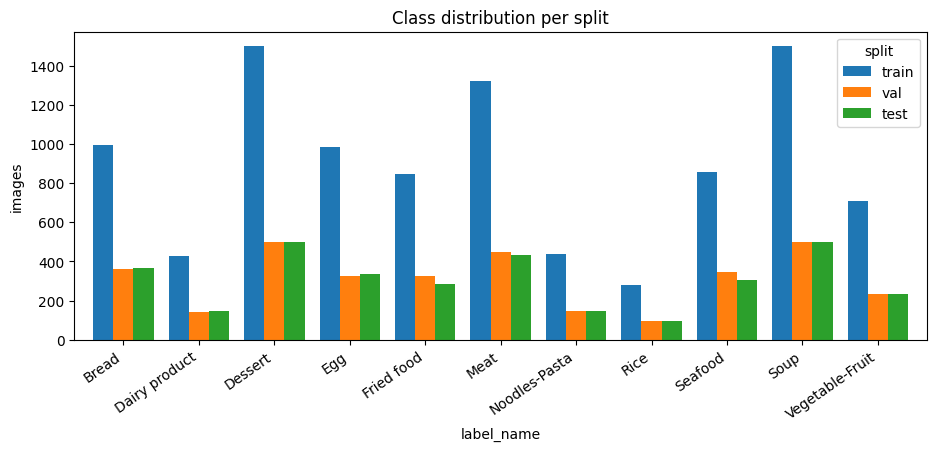

In [ ]:
summary = df.groupby('split').agg(images=('path', 'size'), size_mb=('bytes', lambda s: s.sum() / 2**20),
                                  formats=('fmt', lambda s: ', '.join(sorted(s.unique()))), modes=('mode', lambda s: ', '.join(sorted(s.unique()))))
summary = summary.reindex(['train', 'val', 'test'])
display(summary.round(1))
print(f'Total: {len(df):,} images, {df.bytes.sum()/2**20:.0f} MB on disk')
assert (df.split == 'train').sum() >= 5000, 'Requires >= 5,000 training samples'

cnt = df.pivot_table(index='label_name', columns='split', values='path', aggfunc='size', fill_value=0)[['train', 'val', 'test']]
share = (cnt / cnt.sum() * 100).round(2).add_suffix(' %')
display(pd.concat([cnt, share], axis=1))

def imbalance(c):
	p = c / c.sum()
	max_count = c.max()
	min_count = c.min()
	positive_p = p[p > 0]

	return dict(
		max_min_ratio=float(max_count / min_count) if min_count > 0 else np.inf,
		norm_entropy=float(
			-(positive_p * np.log(positive_p)).sum() / np.log(len(c))
		),
		majority_class=', '.join(c[c == max_count].index),
		majority_share=float(p.max()),
		minority_class=', '.join(c[c == min_count].index),
		minority_share=float(p.min()),
	)

imb = pd.DataFrame({
	s: imbalance(cnt[s])
	for s in cnt.columns
}).T

imb.loc['total'] = imbalance(cnt.sum(axis=1))
display(imb)

tv = {s: 0.5 * np.abs(cnt[s] / cnt[s].sum() - cnt['train'] / cnt['train'].sum()).sum() for s in ['val', 'test']}
print('Total-variation distance of class distribution vs. train:', {k: round(v, 4) for k, v in tv.items()})
cnt.to_csv(TAB_DIR / 'class_distribution.csv')

fig, ax = plt.subplots(figsize=(11, 4))
cnt.plot.bar(ax=ax, width=.8); ax.set_ylabel('images'); ax.set_title('Class distribution per split'); plt.xticks(rotation=35, ha='right')
plt.show()

In [ ]:
TOP_N = 10
size_df = df[df['split'] == 'train']

resolution_counts = (
	size_df.groupby(['w', 'h'])
	.size()
	.sort_values(ascending=False)
)

total_images = len(size_df)
assert total_images > 0, 'Training set is empty'

top_resolutions = resolution_counts.head(TOP_N)

rows = [
	{
		'Rank': rank,
		'Resolution': f'{int(w)} × {int(h)}',
		'Images': int(count),
		'Percentage': count / total_images * 100,
	}
	for rank, ((w, h), count) in enumerate(
		top_resolutions.items(), start=1
	)
]

other_images = total_images - int(top_resolutions.sum())

rows.extend([
	{
		'Rank': '—',
		'Resolution': 'Other',
		'Images': other_images,
		'Percentage': other_images / total_images * 100,
	},
	{
		'Rank': '—',
		'Resolution': 'Total',
		'Images': total_images,
		'Percentage': 100.0,
	},
])

resolution_table = pd.DataFrame(rows)

display(
	resolution_table.style
	.hide(axis='index')
	.format({
		'Images': '{:,.0f}',
		'Percentage': '{:.2f}%',
	})
	.set_caption(
		f'Top {TOP_N} image resolutions in the training set (W × H)'
	)
	.set_properties(**{
		'text-align': 'center',
		'border': '1px solid gray',
	})
	.set_table_styles([
		{
			'selector': 'th',
			'props': [
				('text-align', 'center'),
				('border', '1px solid gray'),
			],
		},
	])
	.apply(
		lambda row: [
			'font-weight: bold' if row['Resolution'] == 'Total' else ''
			for _ in row
		],
		axis=1,
	)
)

Rank,Resolution,Images,Percentage
1,512 × 512,"5,551",56.26%
2,512 × 384,"1,355",13.73%
3,384 × 512,519,5.26%
4,382 × 512,320,3.24%
5,512 × 382,216,2.19%
6,512 × 341,142,1.44%
7,1024 × 768,108,1.09%
8,512 × 306,107,1.08%
9,512 × 289,81,0.82%
10,511 × 512,60,0.61%


# **Representative Training Samples**

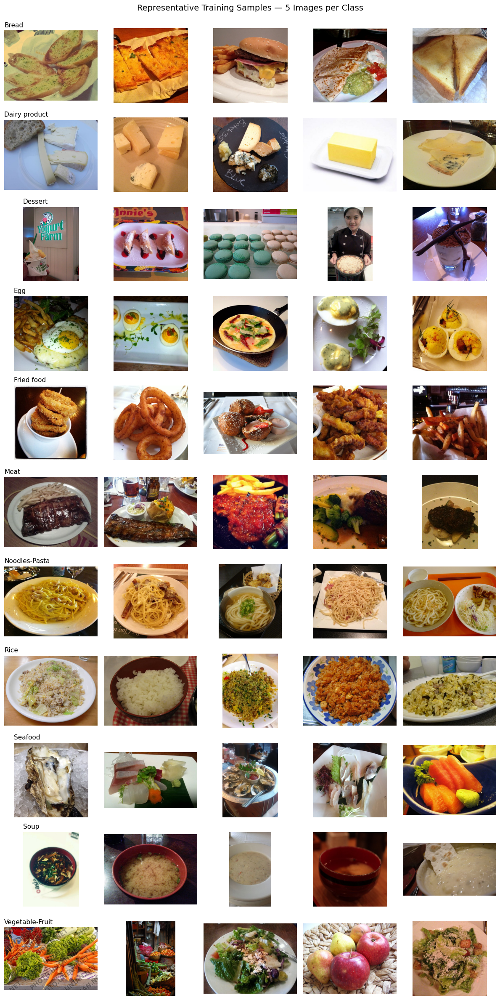

In [ ]:
N_PER_CLASS = 5
sample_df = df[df['split'] == 'train']
fig, axes = plt.subplots(
	len(CLASSES),
	N_PER_CLASS,
	figsize=(12, 2.2 * len(CLASSES)),
	squeeze=False,
)

for row, label in enumerate(CLASSES):
	samples = sample_df[sample_df['label_name'] == label].sample(
		n=N_PER_CLASS,
		random_state=SINGLE_SEED,
	)
	for col, path in enumerate(samples['path']):
		ax = axes[row, col]
		with Image.open(path) as im:
			ax.imshow(im.convert('RGB'))
		ax.axis('off')
		if col == 0:
			ax.set_title(label, fontsize=11, loc='left')

fig.suptitle('Representative Training Samples — 5 Images per Class', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()
plt.close(fig)

# **LEAKAGE PREVENTION**

In [ ]:
splits = ['train', 'val', 'test']
split_pairs = [('train', 'val'), ('train', 'test'), ('val','test'), ('train', 'train'), ('val', 'val'), ('test', 'test'),]
PHASH_THRESHOLD = 10
entries = {
	s: [
		(r.path, r.md5, int(r.phash, 16))
		for r in df.loc[df['split'] == s].itertuples(index=False)
	]
	for s in splits
}

audit, md5_pairs, near_pairs = [], [], []

for a, b in split_pairs:
	md5_count = 0
	near_count = 0

	for path_a, md5_a, hash_a in tqdm(entries[a], desc=f'{a} vs {b}'):
		for path_b, md5_b, hash_b in entries[b]:
			if a == b and path_a >= path_b:
				continue
			if md5_a == md5_b:
				md5_pairs.append((a, b, path_a, path_b, md5_a))
				md5_count += 1
			else:
				distance = (hash_a ^ hash_b).bit_count()
				if distance <= PHASH_THRESHOLD:
					near_pairs.append((a, b, path_a, path_b, distance))
					near_count += 1

	audit.append(dict(
		split_a=a,
		split_b=b,
		md5_duplicate_pairs=md5_count,
		phash_candidate_pairs=near_count,
	))

duplicate_audit = pd.DataFrame(audit)
display(duplicate_audit)

md5_duplicates = pd.DataFrame(
	md5_pairs,
	columns=['split_a', 'split_b', 'path_a', 'path_b', 'md5'],
)
md5_duplicates.to_csv(
	TAB_DIR / 'md5_duplicates.csv', index=False
)

near_duplicates = pd.DataFrame(
	near_pairs,
	columns=['split_a', 'split_b', 'path_a', 'path_b', 'phash_distance'],
).sort_values('phash_distance')

near_duplicates.to_csv(
	TAB_DIR / 'phash_candidates.csv', index=False
)

print(f'MD5 Duplicate: {len(md5_duplicates):,}')
print(f'pHash Near-Duplicates: {len(near_duplicates):,}')

train vs val:   0%|          | 0/9866 [00:00<?, ?it/s]

train vs test:   0%|          | 0/9866 [00:00<?, ?it/s]

val vs test:   0%|          | 0/3430 [00:00<?, ?it/s]

train vs train:   0%|          | 0/9866 [00:00<?, ?it/s]

val vs val:   0%|          | 0/3430 [00:00<?, ?it/s]

test vs test:   0%|          | 0/3347 [00:00<?, ?it/s]

,split_a,split_b,md5_duplicate_pairs,phash_candidate_pairs
0,train,val,51,51
1,train,test,249,46
2,val,test,311,14
3,train,train,5,69
4,val,val,3,7
5,test,test,5,9


MD5 Duplicate: 624
pHash Near-Duplicates: 196


In [ ]:
PHASH_REMOVE_THRESHOLD = 5
assert 0 <= PHASH_REMOVE_THRESHOLD <= PHASH_THRESHOLD
assert df [['md5', 'phash']].notna().all().all()
assert df['path'].is_unique
splits = ['train', 'val', 'test']
priority = {'train': 0, 'val': 1, 'test': 2}
LEAKAGE_POLICY = f'Official splits after dedup'
md5_csv = pd.read_csv(
	TAB_DIR / 'md5_duplicates.csv',
	usecols=['path_a', 'path_b'],
)

phash_csv = pd.read_csv(
	TAB_DIR / 'phash_candidates.csv',
	usecols=['path_a', 'path_b', 'phash_distance'],
)
phash_csv = phash_csv[
	phash_csv['phash_distance'] <= PHASH_REMOVE_THRESHOLD
]
def build_neighbors(pairs):
  neighbors = {}
  for r in pairs.itertuples(index=False):
    neighbors.setdefault(r.path_a, set()).add(r.path_b)
    neighbors.setdefault(r.path_b, set()).add(r.path_a)
  return neighbors

md5_neighbors = build_neighbors(md5_csv)
phash_neighbors = build_neighbors(phash_csv)
def remove_duplicates(frame, neighbors, within_split, description):
  kept_positions = []
  kept_paths = {}
  for i, row in enumerate(tqdm(frame.itertuples(index=False),
                               total=len(frame),
                               desc=description)):
    group = row.split if within_split else 'all'
    references = kept_paths.setdefault(group, set())
    if references.isdisjoint(neighbors.get(row.path, ())):
      kept_positions.append(i)
      references.add(row.path)
  return frame.iloc[kept_positions].copy().reset_index(drop=True)
df_ordered = (
    df.assign(split_priority=df['split'].map(priority))
    .sort_values('split_priority', kind='stable')
    .drop(columns='split_priority')
    .reset_index(drop=True)
)
df_md5_within = remove_duplicates(
	df_ordered, md5_neighbors, True, 'MD5 within splits'
)
df_md5 = remove_duplicates(
	df_md5_within, md5_neighbors, False, 'MD5 across splits'
)

df_phash_within = remove_duplicates(
	df_md5, phash_neighbors, True, 'pHash within splits'
)
df_phash_cross = remove_duplicates(
	df_phash_within, phash_neighbors, False, 'pHash across splits'
)

MANUAL_REMOVE_PATHS = {
	str(DATA_ROOT / 'training' / 'Soup' / '195.jpg'),
	str(DATA_ROOT / 'training' / 'Egg' / '425.jpg'),
}

df_final = (
	df_phash_cross[
		~df_phash_cross['path'].isin(MANUAL_REMOVE_PATHS)
	]
	.copy()
	.reset_index(drop=True)
)

assert df_final['path'].is_unique
assert df_final['md5'].is_unique, 'Duplicate MD5 values remain'
assert (
	df_final['label_name'].map(CLASS_TO_IDX) == df_final['label']
).all(), 'Class labels do not match'

final_splits = {
	s: df_final[df_final['split'] == s].reset_index(drop=True)
	for s in splits
}

train_df = final_splits['train']
val_df = final_splits['val']
test_df = final_splits['test']
SPLIT_COUNTS = {
	name: len(frame)
	for name, frame in final_splits.items()
}
for name, frame in final_splits.items():
	assert not frame.empty, f'{name} split is empty'
	assert set(frame['label']) == set(range(NUM_CLASSES)), (
		f'Missing classes in {name}'
	)

	out = frame[[
		'path', 'split', 'label', 'label_name', 'md5', 'phash'
	]].copy()

	out['path'] = out['path'].map(
		lambda p: Path(p).relative_to(DATA_ROOT).as_posix()
	)

	out.sort_values('path').to_csv(
		SPLIT_DIR / f'{name}.csv',
		index=False,
		lineterminator='\n',
	)

SPLIT_SHA = hashlib.sha256(
	b''.join((SPLIT_DIR / f'{s}.csv').read_bytes() for s in splits)
).hexdigest()

split_config = {
	'dataset': KAGGLE_ROOT,
	'dataset_version': DATASET_VERSION,
	'classes': CLASSES,
	'split_counts': SPLIT_COUNTS,
	'split_sha256': SPLIT_SHA,
	'leakage_policy': LEAKAGE_POLICY,
	'phash_audit_threshold': PHASH_THRESHOLD,
	'phash_remove_threshold': PHASH_REMOVE_THRESHOLD,
	'phash_remove_rule': 'distance <= threshold',
	'manual_remove_paths': sorted(
		Path(p).relative_to(DATA_ROOT).as_posix()
		for p in MANUAL_REMOVE_PATHS
	),
}

(SPLIT_DIR / 'split_config.json').write_text(
	json.dumps(split_config, indent=2),
	encoding='utf-8',
)

counts = pd.DataFrame({
	'original': df.groupby('split').size(),
	'after_md5_within': df_md5_within.groupby('split').size(),
	'after_md5_cross': df_md5.groupby('split').size(),
	'after_phash_within': df_phash_within.groupby('split').size(),
	'after_phash_cross': df_phash_cross.groupby('split').size(),
	'final': pd.Series(SPLIT_COUNTS),
}).reindex(splits).fillna(0).astype(int)

display(counts)
print('Manually removed images:', len(df_phash_cross) - len(df_final))
print('Final split counts:', SPLIT_COUNTS)
print('Total images removed:', len(df) - len(df_final))
print('Final splits saved to:', SPLIT_DIR)
print('Split fingerprint:', SPLIT_SHA)

MD5 within splits:   0%|          | 0/16643 [00:00<?, ?it/s]

MD5 across splits:   0%|          | 0/16631 [00:00<?, ?it/s]

pHash within splits:   0%|          | 0/16020 [00:00<?, ?it/s]

pHash across splits:   0%|          | 0/16002 [00:00<?, ?it/s]

,original,after_md5_within,after_md5_cross,after_phash_within,after_phash_cross,final
train,9866,9861,9861,9848,9848,9846
val,3430,3427,3376,3373,3364,3364
test,3347,3343,2783,2781,2770,2770


Manually removed images: 2
Final split counts: {'train': 9846, 'val': 3364, 'test': 2770}
Total images removed: 663
Final splits saved to: /content/food11_reproduce/food11-256x256-Augmented-fp32/splits
Split fingerprint: 51fd11ab24467622bec13e675d032615bf4a8d0081736530595c11a2c8702470


In [ ]:
TOP_N = 10
size_df = train_df

resolution_counts = (
	size_df.groupby(['w', 'h'])
	.size()
	.sort_values(ascending=False)
)

total_images = len(size_df)
assert total_images > 0, 'Training set is empty'

top_resolutions = resolution_counts.head(TOP_N)

rows = [
	{
		'Rank': rank,
		'Resolution': f'{int(w)} × {int(h)}',
		'Images': int(count),
		'Percentage': count / total_images * 100,
	}
	for rank, ((w, h), count) in enumerate(
		top_resolutions.items(), start=1
	)
]

other_images = total_images - int(top_resolutions.sum())

rows.extend([
	{
		'Rank': '—',
		'Resolution': 'Other',
		'Images': other_images,
		'Percentage': other_images / total_images * 100,
	},
	{
		'Rank': '—',
		'Resolution': 'Total',
		'Images': total_images,
		'Percentage': 100.0,
	},
])

resolution_table = pd.DataFrame(rows)

display(
	resolution_table.style
	.hide(axis='index')
	.format({
		'Images': '{:,.0f}',
		'Percentage': '{:.2f}%',
	})
	.set_caption(
		f'Top {TOP_N} image resolutions in the training set (W × H)'
	)
	.set_properties(**{
		'text-align': 'center',
		'border': '1px solid gray',
	})
	.set_table_styles([
		{
			'selector': 'th',
			'props': [
				('text-align', 'center'),
				('border', '1px solid gray'),
			],
		},
	])
	.apply(
		lambda row: [
			'font-weight: bold' if row['Resolution'] == 'Total' else ''
			for _ in row
		],
		axis=1,
	)
)

Rank,Resolution,Images,Percentage
1,512 × 512,"5,547",56.34%
2,512 × 384,"1,355",13.76%
3,384 × 512,516,5.24%
4,382 × 512,320,3.25%
5,512 × 382,216,2.19%
6,512 × 341,142,1.44%
7,1024 × 768,108,1.10%
8,512 × 306,107,1.09%
9,512 × 289,81,0.82%
10,511 × 512,60,0.61%


In [ ]:
splits = ['train', 'val', 'test']

print(f'Total retained images: {len(df_final):,}')
cnt_final = df_final.pivot_table(
	index='label_name',
	columns='split',
	values='path',
	aggfunc='size',
	fill_value=0,
).reindex(index=CLASSES, columns=splits, fill_value=0)
share_final = (
	(cnt_final / cnt_final.sum() * 100)
	.round(2)
	.add_suffix(' %')
)

display(pd.concat([cnt_final, share_final], axis=1))
imb_final = pd.DataFrame({
	s: imbalance(cnt_final[s])
	for s in splits
}).T

imb_final.loc['total'] = imbalance(cnt_final.sum(axis=1))
display(imb_final)

Total retained images: 15,980


split,train,val,test,train %,val %,test %
label_name,,,,,,
Bread,993,362,268,10.09,10.76,9.68
Dairy product,423,141,147,4.30,4.19,5.31
Dessert,1499,450,440,15.22,13.38,15.88
Egg,982,327,329,9.97,9.72,11.88
Fried food,848,326,221,8.61,9.69,7.98
Meat,1325,449,321,13.46,13.35,11.59
Noodles-Pasta,438,147,147,4.45,4.37,5.31
Rice,279,88,90,2.83,2.62,3.25
Seafood,855,347,203,8.68,10.32,7.33


,max_min_ratio,norm_entropy,majority_class,majority_share,minority_class,minority_share
train,5.37276,0.955548,Dessert,0.152245,Rice,0.028336
val,5.681818,0.957162,Soup,0.148633,Rice,0.026159
test,4.888889,0.964323,Dessert,0.158845,Rice,0.032491
total,5.227571,0.958223,Dessert,0.149499,Rice,0.028598


# **Data Preprocessing**

In [ ]:
def resize_longest_side(image, size=IMG_SIZE):
  w, h = image.size
  scale = size / max(w,h)
  new_size = (
      max(1, round(w*scale)),
      max(1, round(h*scale))
  )
  return image.resize(
      new_size,
      resample=Image.Resampling.BILINEAR
  )
TRAIN_MEAN = [0.485, 0.456, 0.406]
TRAIN_STD = [0.229, 0.224, 0.225]
normalization_config = {
	'source': 'ImageNet-1K',
	'channel_order': 'RGB',
	'input_scale': '0_to_1',
	'mean': TRAIN_MEAN,
	'std': TRAIN_STD
}
(TAB_DIR / 'train_normalization.json').write_text(
	json.dumps(normalization_config, indent=2),
	encoding='utf-8',
)

display(pd.DataFrame({
	'channel': ['R', 'G', 'B'],
	'mean': TRAIN_MEAN,
	'std': TRAIN_STD,
}).set_index('channel').round(6))

print('Training images processed:', len(train_df))
print('Normalization saved to:', TAB_DIR / 'train_normalization.json')

,mean,std
channel,,
R,0.485,0.229
G,0.456,0.224
B,0.406,0.225


Training images processed: 9846
Normalization saved to: /content/food11_reproduce/food11-256x256-Augmented-fp32/tables/train_normalization.json


In [ ]:
PAD_RGB = (0,0,0)
class ResizePad:
  def __init__(self, size, fill):
    self.size = size
    self.fill = fill
  def __call__(self, image):
    image = resize_longest_side(image, self.size)
    canvas = Image.new('RGB', (self.size, self.size), color=self.fill)
    left = (self.size - image.width) // 2
    top = (self.size - image.height) // 2
    canvas.paste(image, (left, top))
    return canvas
train_augmentation = [T.RandomHorizontalFlip(p=HORIZONTAL_FLIP_P)] if HORIZONTAL_FLIP_P else []
train_transform = T.Compose([
    ResizePad(IMG_SIZE, PAD_RGB),
    *train_augmentation,
    T.ToTensor(),
    T.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD)
])
eval_transform = T.Compose([
    ResizePad(IMG_SIZE, PAD_RGB),
    T.ToTensor(),
    T.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD)
])
print('Input size:', (3, IMG_SIZE, IMG_SIZE))
print('Padding RGB:', PAD_RGB)
print(f'Training horizontal flip probability: {HORIZONTAL_FLIP_P}')

Input size: (3, 256, 256)
Padding RGB: (0, 0, 0)
Training horizontal flip probability: 0.5


In [ ]:
class FoodDataset(Dataset):
  def __init__(self, frame, transform):
    self.paths = frame['path'].tolist()
    self.labels = frame['label'].tolist()
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    with Image.open(self.paths[index]) as im:
      image = self.transform(im.convert('RGB'))
    return image, int(self.labels[index])

def make_loaders(seed):
  train_ds = FoodDataset(train_df, train_transform)
  val_ds = FoodDataset(val_df, eval_transform)
  test_ds = FoodDataset(test_df, eval_transform)
  g= torch.Generator().manual_seed(seed)
  train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available(), generator=g)
  val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
  test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
  return train_loader, val_loader, test_loader



# **Baseline Model**

In [ ]:
class SimpleCNN(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES, dropout=0.3):
    super().__init__()
    in_channels = 3
    layers = []
    for out_channels in [16, 32, 64, 128]:
      layers.extend([
          nn.Conv2d(in_channels, out_channels, 3, padding=1),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True),
          nn.MaxPool2d(2)
      ])
      in_channels = out_channels
    self.features = nn.Sequential(*layers)
    self.classifier = nn.Sequential(
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(),
        nn.Dropout(dropout),
        nn.Linear(128, num_classes)
    )
  def forward(self, x):
    return self.classifier(self.features(x))

cnn = SimpleCNN()

print(f'Total parameters: {sum(p.numel() for p in cnn.parameters()):,}')
print(f'Trainable parameters: {sum(p.numel() for p in cnn.parameters() if p.requires_grad):,}')

Total parameters: 99,339
Trainable parameters: 99,339


In [ ]:
class FoodResNet(nn.Module):
  def __init__(self, name, frozen=False,num_classes=NUM_CLASSES, dropout=0.3):
    super().__init__()
    self.frozen = frozen
    if name == 'resnet18':
      self.network = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    else:
      raise ValueError(f'Unknown architecture: {name}')

    in_features = self.network.fc.in_features
    self.network.fc = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(in_features, num_classes)
    )
    if self.frozen:
      self.network.requires_grad_(False)
      self.network.fc.requires_grad_(True)
    self.train()

  def train(self, mode=True):
    super().train(mode)
    if self.frozen:
      self.network.eval()
      self.network.fc.train(mode)
    return self


  def forward(self, x):
    return self.network(x)

def build_model(name, frozen=False):
	if name == 'simple_cnn':
		return SimpleCNN(num_classes=NUM_CLASSES)

	return FoodResNet(
		name=name,
		frozen=frozen,
		num_classes=NUM_CLASSES,
	)

In [ ]:
MODEL_CONFIGS = {
    'simple_cnn': ('simple_cnn', False),
    'resnet18_frozen': ('resnet18', True),
    'resnet18_full': ('resnet18', False),
}
rows = []

for model_id, (architecture, frozen) in MODEL_CONFIGS.items():
	candidate = build_model(architecture, frozen=frozen)

	rows.append({
		'model': model_id,
		'total_parameters': sum(
			p.numel() for p in candidate.parameters()
		),
		'trainable_parameters': sum(
			p.numel() for p in candidate.parameters()
			if p.requires_grad
		),
	})

	del candidate

parameter_table = pd.DataFrame(rows).set_index('model')
display(parameter_table.style.format('{:,}'))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


,total_parameters,trainable_parameters
model,,
simple_cnn,"99,339","99,339"
resnet18_frozen,"11,182,155","5,643"
resnet18_full,"11,182,155","11,182,155"


# **TRAINING & EVALUATION PIPELINE**

In [ ]:
def read_checkpoint(checkpoint_path):
	checkpoint = torch.load(
		checkpoint_path, map_location='cpu', weights_only=True,
	)
	assert checkpoint['classes'] == list(CLASSES), 'Class mapping mismatch'
	assert checkpoint['split_sha256'] == SPLIT_SHA, 'Dataset split mismatch'
	assert checkpoint['image_size'] == IMG_SIZE, 'Image size mismatch'
	assert checkpoint['mean'] == list(TRAIN_MEAN), 'Normalization mean mismatch'
	assert checkpoint['std'] == list(TRAIN_STD), 'Normalization std mismatch'
	return checkpoint

def report_checkpoint(result):
	checkpoint = read_checkpoint(result['checkpoint_path'])
	assert checkpoint['run_name'] == result['run_name'], 'Run name mismatch'
	return checkpoint

def restore_report_model(result, device=None):
	checkpoint = report_checkpoint(result)
	model_id = result['run_name'].rsplit('_seed', 1)[0]
	architecture, frozen = MODEL_CONFIGS[model_id]
	device = torch.device(
		device or ('cuda' if torch.cuda.is_available() else 'cpu')
	)
	with torch.random.fork_rng(devices=[]):
		model = build_model(architecture, frozen=frozen)
	model.load_state_dict(checkpoint['model_state_dict'])
	model.to(device=device, dtype=torch.float32).eval()
	return model, checkpoint, model_id, device

def finish_report_figure(fig, filename, save=True):
	if save:
		fig.savefig(
			FIG_DIR / filename,
			dpi=180,
			bbox_inches='tight',
		)
	plt.show()
	plt.close(fig)

def load_saved_result(run_name):
	paths = {
		'checkpoint_path': CKPT_DIR / f'{run_name}_best.pt',
		'history': LOG_DIR / f'{run_name}_history.csv',
		'test_metrics': TAB_DIR / f'{run_name}_test_metrics.csv',
		'per_class_metrics': TAB_DIR / f'{run_name}_per_class_metrics.csv',
		'predictions': TAB_DIR / f'{run_name}_test_predictions.csv',
		'confusion_matrix': TAB_DIR / f'{run_name}_confusion_matrix.csv',
	}
	missing = [
		str(path)
		for path in paths.values()
		if not path.is_file()
	]

	if missing:
		raise FileNotFoundError(
			'Missing saved results:\n' + '\n'.join(missing)
		)

	result = {
		'run_name': run_name,
		'checkpoint_path': paths['checkpoint_path'],
	}

	checkpoint = report_checkpoint(result)
	config = checkpoint.get('config', {})
	config_path = LOG_DIR / f'{run_name}_config.json'

	if config_path.is_file():
		saved = json.loads(config_path.read_text(encoding='utf-8'))
		if saved['status'] != 'complete':
			raise RuntimeError(
				f'{run_name}: previous training/evaluation did not finish.'
			)
		config = saved['config']

	history = pd.read_csv(paths['history'])
	metrics = pd.read_csv(paths['test_metrics']).iloc[0]
	selected = history[history['epoch'] == checkpoint['epoch']]

	assert len(selected) == 1, 'Checkpoint epoch is missing from history'
	assert metrics['run_name'] == run_name, 'Saved metrics run mismatch'
	assert int(metrics['seed']) == checkpoint['seed'], 'Saved metrics seed mismatch'
	assert int(metrics['best_epoch']) == checkpoint['epoch'], 'Saved metrics checkpoint mismatch'

	for key in METRIC_KEYS:
		assert np.isclose(
			selected.iloc[0][f'val_{key}'],
			checkpoint['val_metrics'][key],
		), f'History/checkpoint mismatch: {key}'

	if config:
		assert len(history) == config['epochs'], 'Saved training is incomplete'

	result.update({
		'history': history,
		'test_metrics': {
			key: float(metrics[key])
			for key in METRIC_KEYS
		},
		'per_class_metrics': pd.read_csv(paths['per_class_metrics']),
		'predictions': pd.read_csv(paths['predictions']),
		'confusion_matrix': pd.read_csv(
			paths['confusion_matrix'], index_col=0,
		),
		'config': config,
	})
	print('Loaded:', run_name)
	return result

In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None):
  training = optimizer is not None
  model.train(training)
  total_loss, total_samples = 0.0, 0
  y_true, y_pred = [], []
  with torch.set_grad_enabled(training):
    for images, labels in loader:
      images = images.to(device, dtype=torch.float32)
      labels = labels.to(device, dtype=torch.long)
      if training:
        optimizer.zero_grad(set_to_none=True)
      logits = model(images)
      loss = criterion(logits, labels)
      if training:
        loss.backward()
        optimizer.step()
      total_loss += loss.item() * labels.size(0)
      total_samples += labels.size(0)
      y_true.extend(labels.detach().cpu().tolist())
      y_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())
  precision, recall, f1, _ = precision_recall_fscore_support(
      y_true, y_pred,
      labels=list(range(NUM_CLASSES)),
      average='macro',
      zero_division=0
  )
  metrics = {
      'loss': total_loss / total_samples,
      'accuracy': float(accuracy_score(y_true, y_pred)),
      'macro_precision': float(precision),
      'macro_recall': float(recall),
      'macro_f1': float(f1)
  }
  return metrics, np.asarray(y_true), np.asarray(y_pred)

def fit(model, train_loader, val_loader, optimizer, criterion, device,
        run_name, epochs=EPOCHS, scheduler=None, config=None):
  assert epochs > 0
  checkpoint_path = CKPT_DIR / f'{run_name}_best.pt'
  history_path = LOG_DIR / f'{run_name}_history.csv'
  best_f1, best_loss = float('-inf'), float('inf')
  history = []
  for epoch in range(1, epochs +1):
    start = time.perf_counter()
    train_metrics, _, _ = run_epoch(model, train_loader, criterion, device, optimizer=optimizer)
    val_metrics, _, _ = run_epoch(model, val_loader, criterion, device)
    elapsed = time.perf_counter() - start
    history.append({
        'epoch': epoch,
        **{f'train_{k}': v for k, v in train_metrics.items()},
        **{f'val_{k}': v for k, v in val_metrics.items()},
        'lr': optimizer.param_groups[0]['lr'],
        **{f'lr_{group["name"]}': group['lr'] for group in optimizer.param_groups},
        'epoch_seconds': elapsed
    })
    if val_metrics['macro_f1'] > best_f1 or (val_metrics['macro_f1'] == best_f1 and val_metrics['loss'] < best_loss):
      best_f1 = val_metrics['macro_f1']
      best_loss = val_metrics['loss']
      torch.save({
          'model_state_dict': model.state_dict(),
          'epoch': epoch,
          'run_name': run_name,
          'seed': int(SINGLE_SEED),
          'classes': list(CLASSES),
          'split_sha256': SPLIT_SHA,
          'image_size': IMG_SIZE,
          'mean': list(TRAIN_MEAN),
          'std': list(TRAIN_STD),
          'val_metrics': val_metrics,
          'config': config or {}
      }, checkpoint_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    print(f'Epoch {epoch}/{epochs} | Time: {elapsed:.1f}s')
    for name, metrics in [('Train', train_metrics), ('Validation', val_metrics)]:
      print(f'{name} | ' + ' | '.join(f'{key}: {value:.4f}' for key, value in metrics.items()))
    if scheduler is not None:
      scheduler.step(val_metrics['loss'])
  return pd.DataFrame(history), checkpoint_path

def evaluate(model, test_loader, criterion, device, checkpoint_path):
  checkpoint = read_checkpoint(checkpoint_path)
  assert checkpoint['classes'] == list(CLASSES), 'Class mapping mismatch'
  assert checkpoint['split_sha256'] == SPLIT_SHA, 'Dataset split mismatch'
  assert checkpoint['image_size'] == IMG_SIZE, 'Image size mismatch'
  assert (checkpoint['mean'] == list(TRAIN_MEAN) and checkpoint['std'] == list(TRAIN_STD)), 'Normalization mismatch'
  model.to(device=device, dtype=torch.float32)
  model.load_state_dict(checkpoint['model_state_dict'])
  metrics, y_true, y_pred = run_epoch(
		model, test_loader, criterion, device,
	)
  run_name = checkpoint['run_name']
  predictions = pd.DataFrame({
		'path': test_loader.dataset.paths,
		'true_label': y_true,
		'predicted_label': y_pred,
		'true_class': [CLASSES[i] for i in y_true],
		'predicted_class': [CLASSES[i] for i in y_pred],
	})
  precision, recall, f1, support = precision_recall_fscore_support(
		y_true,
		y_pred,
		labels=list(range(NUM_CLASSES)),
		average=None,
		zero_division=0,
	)
  per_class_metrics = pd.DataFrame({
		'class': CLASSES,
		'precision': precision,
		'recall': recall,
		'f1': f1,
		'support': support.astype(int),
	})
  cm = pd.DataFrame(
		confusion_matrix(
			y_true, y_pred, labels=list(range(NUM_CLASSES)),
		),
		index=CLASSES,
		columns=CLASSES,
	).rename_axis(
		index='true_class',
		columns='predicted_class',
	)
  pd.DataFrame([{
		'run_name': run_name,
		'seed': checkpoint['seed'],
		'best_epoch': checkpoint['epoch'],
		**metrics,
	}]).to_csv(
		TAB_DIR / f'{run_name}_test_metrics.csv',
		index=False,
	)
  predictions.to_csv(
		TAB_DIR / f'{run_name}_test_predictions.csv',
		index=False,
	)
  per_class_metrics.to_csv(
		TAB_DIR / f'{run_name}_per_class_metrics.csv',
		index=False,
	)
  cm.to_csv(
		TAB_DIR / f'{run_name}_confusion_matrix.csv'
	)
  print(f'Test results | Selected epoch: {checkpoint["epoch"]}')
  print(' | '.join(f'{key}: {value:.4f}' for key, value in metrics.items()))
  display(per_class_metrics.round(4))
  return metrics, per_class_metrics, predictions, cm

In [ ]:
import importlib.metadata as metadata

def collect_environment(device):
	device = torch.device(device)
	using_cuda = device.type == 'cuda'
	properties = (
		torch.cuda.get_device_properties(device)
		if using_cuda else None
	)
	packages = [
		'torch',
		'torchvision',
		'numpy',
		'pandas',
		'scikit-learn',
		'scipy',
		'matplotlib',
		'Pillow',
		'kagglehub',
	]

	versions = {}
	for package in packages:
		try:
			versions[package] = metadata.version(package)
		except metadata.PackageNotFoundError:
			versions[package] = None

	return {
		'python_version': platform.python_version(),
		'platform': platform.platform(),
		'device': str(device),
		'gpu_name': properties.name if using_cuda else None,
		'gpu_memory_gb': (
			round(properties.total_memory / 2**30, 2)
			if using_cuda else None
		),
		'cuda_version': torch.version.cuda,
		'dependencies': versions,
	}

In [ ]:
def run_experiment(name):
	if name not in MODEL_CONFIGS:
		raise ValueError(f'Unknown model: {name}')
	run_name = f'{name}_seed{SINGLE_SEED}'
	if not TRAIN_MODELS:
		return load_saved_result(run_name)
	set_seed(SINGLE_SEED)
	train_loader, val_loader, test_loader = make_loaders(SINGLE_SEED)
	architecture, frozen = MODEL_CONFIGS[name]
	device = torch.device(
		'cuda' if torch.cuda.is_available() else 'cpu'
	)
	model = build_model(architecture, frozen=frozen).to(
		device=device,
		dtype=torch.float32,
	)
	criterion = nn.CrossEntropyLoss()
	if isinstance(model, FoodResNet) and not model.frozen:
		parameter_groups = [
			{
				'name': 'backbone',
				'params': [
					p
					for key, p in model.network.named_parameters()
					if not key.startswith('fc.') and p.requires_grad
				],
				'lr': BACKBONE_LR,
			},
			{
				'name': 'head',
				'params': list(model.network.fc.parameters()),
				'lr': LR,
			},
		]
	else:
		parameter_groups = [{
			'name': 'head' if frozen else 'model',
			'params': [
				p for p in model.parameters()
				if p.requires_grad
			],
			'lr': LR,
		}]

	optimizer = torch.optim.AdamW(
		parameter_groups,
		weight_decay=WEIGHT_DECAY,
	)

	scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
		optimizer,
		mode='min',
		factor=0.5,
		patience=3,
		min_lr=1e-6,
	)

	config = {
		'model': name,
		'architecture': architecture,
		'frozen': frozen,
		'seed': int(SINGLE_SEED),
		'epochs': int(EPOCHS),
		'batch_size': train_loader.batch_size,
		'num_workers': train_loader.num_workers,
		'image_size': IMG_SIZE,
		'optimizer': 'AdamW',
		'initial_lrs': {
			g['name']: g['lr']
			for g in optimizer.param_groups
		},
		'weight_decay': WEIGHT_DECAY,
		'scheduler': 'ReduceLROnPlateau',
		'scheduler_factor': 0.5,
		'scheduler_patience': 3,
		'scheduler_min_lr': 1e-6,
		'selection': 'max_val_macro_f1_then_min_val_loss',
		'mean': list(TRAIN_MEAN),
		'std': list(TRAIN_STD),
		'split_sha256': SPLIT_SHA,
		'training_hardware': (
			torch.cuda.get_device_name(device)
			if device.type == 'cuda'
			else platform.processor() or platform.machine()
		),
    'environment': collect_environment(device),
	}
	config_path = LOG_DIR / f'{run_name}_config.json'
	config_path.write_text(
		json.dumps({
			'status': 'training',
			'config': config,
		}, indent=2),
		encoding='utf-8',
	)
	print(
		f'Training: {run_name} | '
		f'Device: {device} | Epochs: {EPOCHS}'
	)
	history, checkpoint_path = fit(model,train_loader,val_loader,optimizer,criterion,
                                device,run_name,epochs=EPOCHS,scheduler=scheduler,config=config)
	metrics, per_class, predictions, cm = evaluate(model,test_loader,criterion,device,checkpoint_path,)

	config_path.write_text(
		json.dumps({
			'status': 'complete',
			'config': config,
		}, indent=2),
		encoding='utf-8',
	)
	return {
		'run_name': run_name,
		'history': history,
		'checkpoint_path': checkpoint_path,
		'test_metrics': metrics,
		'per_class_metrics': per_class,
		'predictions': predictions,
		'confusion_matrix': cm,
		'config': config,
	}

In [ ]:
cnn_result = run_experiment('simple_cnn')

Loaded: simple_cnn_seed42


In [ ]:
resnet18_frozen_result = run_experiment('resnet18_frozen')

Loaded: resnet18_frozen_seed42


In [ ]:
resnet18_full_result = run_experiment('resnet18_full')

Loaded: resnet18_full_seed42


In [ ]:
SD_DDOF = 1
REPORT_BATCH_SIZE = 32
BENCHMARK_WARMUP = 5
BENCHMARK_REPEATS = 20
MODEL_NAMES = ['simple_cnn', 'resnet18_frozen', 'resnet18_full']
assert all(name in MODEL_CONFIGS for name in MODEL_NAMES)
def report_std(values, axis=0):
	values = np.asarray(values, dtype=np.float64)
	if values.shape[axis] <= SD_DDOF:
		return np.full(np.mean(values, axis=axis).shape, np.nan)
	return values.std(axis=axis, ddof=SD_DDOF)

def mean_std_text(mean, std, digits=4):
	return f'{mean:.{digits}f} \u00b1 {std:.{digits}f}'

def group_report_results(results, expected_seeds=None):
	names = [r['run_name'] for r in results]
	groups = {}
	for result in results:
		checkpoint = report_checkpoint(result)
		model_id = result['run_name'].rsplit('_seed', 1)[0]
		if result['run_name'] != f'{model_id}_seed{int(checkpoint["seed"])}':
			raise ValueError('Run name/checkpoint seed mismatch')
		groups.setdefault(model_id, []).append(result)
	for model_id, group in groups.items():
		group.sort(key=lambda r: int(r['run_name'].rsplit('_seed', 1)[1]))
		seeds = [int(r['run_name'].rsplit('_seed', 1)[1]) for r in group]
		if len(set(seeds)) != len(seeds):
			raise ValueError(f'Duplicate seeds for {model_id}')
		if expected_seeds is not None and set(seeds) != set(expected_seeds):
			raise ValueError(f'{model_id}: expected seeds {expected_seeds}, got {seeds}')
		configs = [r['config'] for r in group]
		excluded = {'seed', 'training_hardware', 'torch_version', 'environment'}
		signatures = {
			json.dumps({k:v for k,v in c.items() if k not in excluded}, sort_keys=True)
			for c in configs
		}
		if len(signatures) > 1:
			raise ValueError(f'Different training configurations for {model_id}')
		hardware = {c['training_hardware'] for c in configs}
		if len(hardware) > 1:
			print(f'{model_id}: training times came from different hardware.')
	return groups

def class_tables_from_predictions(predictions):
	if predictions.empty or not predictions['path'].is_unique:
		raise ValueError('Predictions must contain unique image paths')
	expected = test_df.set_index('path')['label'].sort_index()
	actual = predictions.set_index('path')['true_label'].sort_index()
	if not actual.index.equals(expected.index) or not np.array_equal(actual.to_numpy(), expected.to_numpy()):
		raise ValueError('Prediction paths/labels do not match the current test split')
	y_true = predictions['true_label'].to_numpy(dtype=int)
	y_pred = predictions['predicted_label'].to_numpy(dtype=int)
	if not np.isin(y_pred, np.arange(NUM_CLASSES)).all():
		raise ValueError('Invalid predicted class index')
	values = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
	cm = pd.DataFrame(values, index=CLASSES, columns=CLASSES).rename_axis(
		index='true_class', columns='predicted_class',
	)
	precision, recall, f1, support = precision_recall_fscore_support(
		y_true, y_pred, labels=list(range(NUM_CLASSES)),
		average=None, zero_division=0,
	)
	tp = np.diag(values)
	fn = values.sum(axis=1) - tp
	fp = values.sum(axis=0) - tp
	tn = values.sum() - tp - fn - fp
	per_class = pd.DataFrame({
		'class':CLASSES, 'accuracy_ovr':(tp+tn)/values.sum(),
		'precision':precision, 'recall':recall, 'f1':f1, 'support':support.astype(int),
	})
	return cm, per_class

In [ ]:
def training_behavior(results, output_prefix, save=True):
	groups = group_report_results(results)
	seed_colors = {seed:f'C{i}' for i,seed in enumerate(THREE_SEEDS)}
	metrics = ['loss', 'accuracy', 'macro_f1']
	titles = ['Cross-entropy loss', 'Accuracy', 'Macro-F1']
	summaries = []

	for model_id, group in groups.items():
		fig, axes = plt.subplots(3, 1, figsize=(11, 13))
		last_epoch = 0

		for result in group:
			checkpoint = report_checkpoint(result)
			h = result['history'].sort_values('epoch').reset_index(drop=True)
			best_epoch = int(checkpoint['epoch'])
			selected = h[h['epoch'] == best_epoch]
			if len(selected) != 1 or h['epoch'].duplicated().any():
				raise ValueError('Selected epoch is missing or history contains duplicate epochs')
			best = selected.iloc[0]
			seed = int(checkpoint['seed'])
			color = seed_colors[seed]
			last_epoch = max(last_epoch, h['epoch'].max())

			for ax, metric in zip(axes, metrics):
				scale = 1 if metric == 'loss' else 100
				ax.plot(
					h['epoch'], h[f'train_{metric}'] * scale,
					color=color, linestyle='-', label=f'Train, seed {seed}',
				)
				ax.plot(
					h['epoch'], h[f'val_{metric}'] * scale,
					color=color, linestyle='--',
					label=f'Val, seed {seed} (selected epoch {best_epoch})',
				)
				ax.axvline(best_epoch, color=color, linestyle=':', alpha=0.7)
				ax.scatter(
					best_epoch, best[f'val_{metric}'] * scale,
					color=color, s=35, zorder=5,
				)

			summaries.append({
				'model':model_id, 'run_name':result['run_name'], 'seed':seed,
				'epochs_run':len(h), 'selected_epoch':best_epoch,
				'selected_val_loss':best['val_loss'],
				'selected_val_accuracy':best['val_accuracy'],
				'selected_val_macro_f1':best['val_macro_f1'],
				'train_minus_val_f1_pp':100*(best['train_macro_f1']-best['val_macro_f1']),
				'last_val_loss_minus_min':h['val_loss'].iloc[-1]-h['val_loss'].min(),
				'training_time_minutes':h['epoch_seconds'].sum()/60,
				'mean_epoch_seconds':h['epoch_seconds'].mean(),
			})

		for ax, metric, title in zip(axes, metrics, titles):
			ax.set(
				title=f'{model_id}: {title} across training seeds',
				xlabel='Epoch',
				ylabel=title if metric == 'loss' else f'{title} (%)',
				xlim=(0.5, last_epoch + 0.5),
			)
			if metric != 'loss':
				ax.set_ylim(0, 100)
			ax.grid(alpha=0.3, linestyle='--')
			ax.legend(fontsize=8, ncol=2)

		fig.tight_layout(h_pad=3)
		finish_report_figure(
			fig, f'{output_prefix}_{model_id}_learning_curves.png', save,
		)

	summary = pd.DataFrame(summaries)
	display(summary.round(4))
	if save:
		summary.to_csv(TAB_DIR / f'{output_prefix}_training_summaries.csv', index=False)
	return summary

def quantitative_results(
	results, batch_size=32, warmup=5, repeats=20,
	device=None, save=True, recompute_test=False, output_prefix='evaluation',
):
	if batch_size <= 0 or warmup < 0 or repeats <= 0:
		raise ValueError('Invalid batch size, warmup or repeats')
	groups = group_report_results(results)
	results = [r for group in groups.values() for r in group]
	test_loader = None
	if recompute_test:
		test_loader = DataLoader(
			FoodDataset(test_df, eval_transform), batch_size=batch_size,
			shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available(),
		)
	rows = []
	for result in results:
		model, checkpoint, model_id, run_device = restore_report_model(result, device)
		try:
			if recompute_test:
				print('Recomputing test metrics:', result['run_name'])
				test_metrics, y_true, y_pred = run_epoch(
					model, test_loader, nn.CrossEntropyLoss(), run_device,
				)
				predictions = pd.DataFrame({
					'path':test_loader.dataset.paths, 'true_label':y_true,
					'predicted_label':y_pred,
					'true_class':[CLASSES[int(i)] for i in y_true],
					'predicted_class':[CLASSES[int(i)] for i in y_pred],
				})
				result.update({
					'test_metrics':test_metrics,
					'predictions':predictions,
				})
			else:
				print('Using saved test metrics:', result['run_name'])
				test_metrics = {key:float(result['test_metrics'][key]) for key in METRIC_KEYS}
			cm, per_class = class_tables_from_predictions(result['predictions'])
			if not recompute_test:
				assert np.array_equal(
					cm.to_numpy(), result['confusion_matrix'].loc[CLASSES, CLASSES].to_numpy(),
				), 'Confusion matrix does not match predictions'
			result.update({'confusion_matrix':cm, 'per_class_metrics':per_class})
			expected_metrics = {
				'accuracy':np.trace(cm.to_numpy())/cm.to_numpy().sum(),
				'macro_precision':per_class['precision'].mean(),
				'macro_recall':per_class['recall'].mean(),
				'macro_f1':per_class['f1'].mean(),
			}
			for key, expected in expected_metrics.items():
				if not np.isclose(test_metrics[key], expected, rtol=1e-5, atol=1e-7):
					raise ValueError(f'Test metrics/predictions mismatch: {key}')
			if not all(np.isfinite(float(test_metrics[key])) for key in METRIC_KEYS):
				raise ValueError('Non-finite test metric')

			print('Benchmarking inference:', result['run_name'], '| Device:', run_device)
			import torch.utils.benchmark as benchmark

			model.eval()

			x = torch.zeros(
				1, 3, checkpoint['image_size'], checkpoint['image_size'],
				device=run_device,
				dtype=torch.float32,
			)

			with torch.inference_mode():
				timer = benchmark.Timer(
					stmt='model(x)',
					globals={'model': model, 'x': x},
					num_threads=torch.get_num_threads(),
				)
				measurement = timer.blocked_autorange(min_run_time=2.0)

			inference_ms = measurement.median * 1000
			del x
			h = result['history']
			config = result['config']
			rows.append({
				'model':model_id, 'run_name':result['run_name'], 'seed':int(checkpoint['seed']),
				'selected_epoch':int(checkpoint['epoch']), 'epochs_run':len(h),
				'image_size':int(checkpoint['image_size']),
				'total_parameters':sum(p.numel() for p in model.parameters()),
				'trainable_parameters':sum(p.numel() for p in model.parameters() if p.requires_grad),
				**{f'test_{key}':float(test_metrics[key]) for key in METRIC_KEYS},
				'test_metrics_source':'recomputed' if recompute_test else 'saved',
				'training_time_minutes':float(h['epoch_seconds'].sum()/60),
				'mean_epoch_seconds':float(h['epoch_seconds'].mean()),
				'inference_time_ms_per_image':inference_ms,
				'inference_batch_size':1, 'inference_device':str(run_device),
				'inference_hardware':(
					torch.cuda.get_device_name(run_device) if run_device.type == 'cuda'
					else platform.machine()
				),
				'training_hardware':config['training_hardware'],
				'recorded_config':json.dumps(config),
			})
		finally:
			del model, checkpoint
			gc.collect()
			if run_device.type == 'cuda':
				torch.cuda.empty_cache()
	runs = pd.DataFrame(rows)
	metrics = [
		'test_macro_f1','test_accuracy','test_macro_precision','test_macro_recall','test_loss',
		'training_time_minutes','mean_epoch_seconds','inference_time_ms_per_image',
	]
	summary_rows, report_rows = [], []
	for model_id, group in runs.groupby('model', sort=False):
		for column in ['total_parameters','trainable_parameters','image_size','epochs_run']:
			if group[column].nunique() != 1:
				raise ValueError(f'Inconsistent {column} for {model_id}')
		row = {
			'model':model_id, 'n_runs':len(group), 'std_ddof':SD_DDOF,
			'total_parameters':int(group['total_parameters'].iloc[0]),
			'trainable_parameters':int(group['trainable_parameters'].iloc[0]),
		}
		formatted = dict(row)
		for metric in metrics:
			values = group[metric].to_numpy(dtype=float)
			row[f'{metric}_mean'] = values.mean()
			row[f'{metric}_std'] = float(report_std(values))
			formatted[metric] = (
				float(values[0]) if len(group)==1
				else mean_std_text(row[f'{metric}_mean'], row[f'{metric}_std'])
			)
		summary_rows.append(row)
		report_rows.append(formatted)
	summary, report = pd.DataFrame(summary_rows), pd.DataFrame(report_rows)
	display(runs.drop(columns='recorded_config').round(4))
	display(report.round(4))
	fig, axes = plt.subplots(1,2,figsize=(13,5))
	positions = np.arange(len(summary))
	for ax, metric, title in zip(
		axes, ['test_macro_f1','test_accuracy'], ['Test Macro-F1','Test Accuracy'],
	):
		means = summary[f'{metric}_mean'].to_numpy()*100
		ax.bar(positions, means)
		for i, row in summary.iterrows():
			sd = row[f'{metric}_std']
			if row['n_runs']>1 and np.isfinite(sd):
				ax.errorbar(i, means[i], yerr=100*sd, color='black', capsize=4)
		ax.set_xticks(positions)
		ax.set_xticklabels(summary['model'], rotation=30, ha='right')
		ax.set(title=title, ylabel='Score (%)', ylim=(0,100))
		ax.grid(axis='y', alpha=0.3)
	fig.tight_layout()
	finish_report_figure(fig, f'{output_prefix}_quantitative_comparison.png', save)
	if save:
		runs.to_csv(TAB_DIR/f'{output_prefix}_runs_quantitative.csv',index=False)
		summary.to_csv(TAB_DIR/f'{output_prefix}_models_mean_std.csv',index=False)
		report.to_csv(TAB_DIR/f'{output_prefix}_models_report.csv',index=False)
		for result in results:
			result['predictions'].to_csv(
				TAB_DIR/f'{output_prefix}_{result["run_name"]}_predictions.csv',index=False,
			)
	print('Training time includes validation and excludes checkpoint/CSV writes.')
	print('Inference: FP32 forward only, synthetic input, batch size 1; no data loading or transfers.')
	print(f'SD uses ddof={SD_DDOF} across runs, not across benchmark repetitions.')
	print('Recomputed results update this session; original per-run evaluation files are preserved.')
	return runs, summary


In [ ]:
def class_results(results, output_prefix, save=True):
	outputs = {}
	for model_id, group in group_report_results(results).items():
		matrices = [
			result['confusion_matrix'].loc[CLASSES, CLASSES].to_numpy(dtype=float)
			for result in group
		]
		class_frames = [
			result['per_class_metrics'].set_index('class').loc[CLASSES]
			for result in group
		]
		counts = np.stack(matrices)
		supports = counts.sum(axis=2)
		if not np.all(supports==supports[0]):
			raise ValueError('Test class supports differ across runs')
		totals = counts.sum(axis=2,keepdims=True)
		assert (totals > 0).all(), 'Each test class must have at least one image'
		normalized = counts / totals * 100
		count_mean, count_std = counts.mean(axis=0), report_std(counts)
		percent_mean, percent_std = normalized.mean(axis=0), report_std(normalized)
		multiple = len(group)>1
		def matrix_frame(values):
			return pd.DataFrame(values,index=CLASSES,columns=CLASSES).rename_axis(
				index='true_class',columns='predicted_class',
			)
		count_report, percent_report = matrix_frame(count_mean).astype(object), matrix_frame(percent_mean).astype(object)
		for i in range(NUM_CLASSES):
			for j in range(NUM_CLASSES):
				count_report.iat[i,j] = (
					mean_std_text(count_mean[i,j],count_std[i,j],1)
					if multiple else str(int(count_mean[i,j]))
				)
				percent_report.iat[i,j] = (
					mean_std_text(percent_mean[i,j],percent_std[i,j],1)+'%'
					if multiple else f'{percent_mean[i,j]:.1f}%'
				)
		per_class_summary = pd.DataFrame(index=pd.Index(CLASSES,name='class'))
		per_class_report = per_class_summary.copy()
		for metric in ['accuracy_ovr','precision','recall','f1']:
			values = np.stack([frame[metric].to_numpy() for frame in class_frames])
			means, stds = values.mean(axis=0), report_std(values)
			per_class_summary[f'{metric}_mean'] = means
			per_class_summary[f'{metric}_std'] = stds
			per_class_report[metric] = (
				[mean_std_text(m,s) for m,s in zip(means,stds)] if multiple else means
			)
		per_class_summary['support'] = supports[0].astype(int)
		per_class_report['support'] = supports[0].astype(int)
		per_class_summary['n_runs'] = len(group)
		per_class_summary['std_ddof'] = SD_DDOF
		fig, axes = plt.subplots(1,2,figsize=(25,11))
		for ax, means, stds, title, vmax in [
			(axes[0],count_mean,count_std,'Confusion counts',None),
			(axes[1],percent_mean,percent_std,'Row-normalized confusion (%)',100),
		]:
			im = ax.imshow(means,cmap='Blues',vmin=0,vmax=vmax)
			fig.colorbar(im,ax=ax,fraction=0.046)
			ax.set_xticks(range(NUM_CLASSES))
			ax.set_yticks(range(NUM_CLASSES))
			ax.set_xticklabels(CLASSES,rotation=60,ha='right',fontsize=8)
			ax.set_yticklabels(CLASSES,fontsize=8)
			ax.set(title=title+(': mean \u00b1 SD' if multiple else ''),xlabel='Predicted class',ylabel='True class')
			for i in range(NUM_CLASSES):
				for j in range(NUM_CLASSES):
					text = (
						f'{means[i,j]:.1f}\n\u00b1 {stds[i,j]:.1f}' if multiple
						else f'{means[i,j]:.1f}' if vmax else str(int(means[i,j]))
					)
					ax.text(j,i,text,ha='center',va='center',fontsize=13,
						color='white' if im.norm(means[i,j])>0.5 else 'black')
		fig.suptitle(f'{model_id}: {len(group)} run(s), SD ddof={SD_DDOF}')
		fig.tight_layout(rect=[0,0,1,0.96])
		stem = f'{output_prefix}_{model_id}'
		finish_report_figure(fig,f'{stem}_confusion_matrices.png',save)
		f1_values = np.stack([frame['f1'].to_numpy() for frame in class_frames])
		f1_mean, f1_std = f1_values.mean(axis=0)*100, report_std(f1_values)*100
		fig, ax = plt.subplots(figsize=(10,6))
		ax.barh(CLASSES,f1_mean)
		if multiple:
			ax.errorbar(f1_mean,np.arange(NUM_CLASSES),xerr=f1_std,fmt='none',color='black',capsize=3)
		ax.invert_yaxis()
		ax.set(title=f'{model_id}: per-class F1'+(' (mean \u00b1 SD)' if multiple else ''),
			xlabel='F1 (%)',xlim=(0,100))
		ax.grid(axis='x',alpha=0.3)
		fig.tight_layout()
		finish_report_figure(fig,f'{stem}_per_class_f1.png',save)
		print('\nModel:',model_id,'| Confusion counts')
		display(count_report)
		print('Row-normalized confusion: mean in percent, SD in percentage points')
		display(percent_report)
		display(per_class_report.round(4))
		tables = {
			'confusion_count_mean':matrix_frame(count_mean),'confusion_count_std':matrix_frame(count_std),
			'confusion_count_report':count_report,
			'confusion_percent_mean':matrix_frame(percent_mean),'confusion_percent_std':matrix_frame(percent_std),
			'confusion_percent_report':percent_report,
			'per_class_mean_std':per_class_summary,'per_class_report':per_class_report,
		}
		if save:
			for name,table in tables.items():
				table.to_csv(TAB_DIR/f'{stem}_{name}.csv')
		outputs[model_id] = tables
	return outputs


# **Single Seed**

In [ ]:
SINGLE_REPORT_SEED = SINGLE_SEED
single_prefix = f'single_seed{SINGLE_REPORT_SEED}'
single_seed_results = [
	cnn_result,
	resnet18_frozen_result,
	resnet18_full_result,
]
assert [
	r['run_name'] for r in single_seed_results
] == [f'{name}_seed{SINGLE_REPORT_SEED}' for name in MODEL_NAMES]
group_report_results(single_seed_results, expected_seeds=[SINGLE_REPORT_SEED])
print('Single-seed report:', SINGLE_REPORT_SEED)


Single-seed report: 42


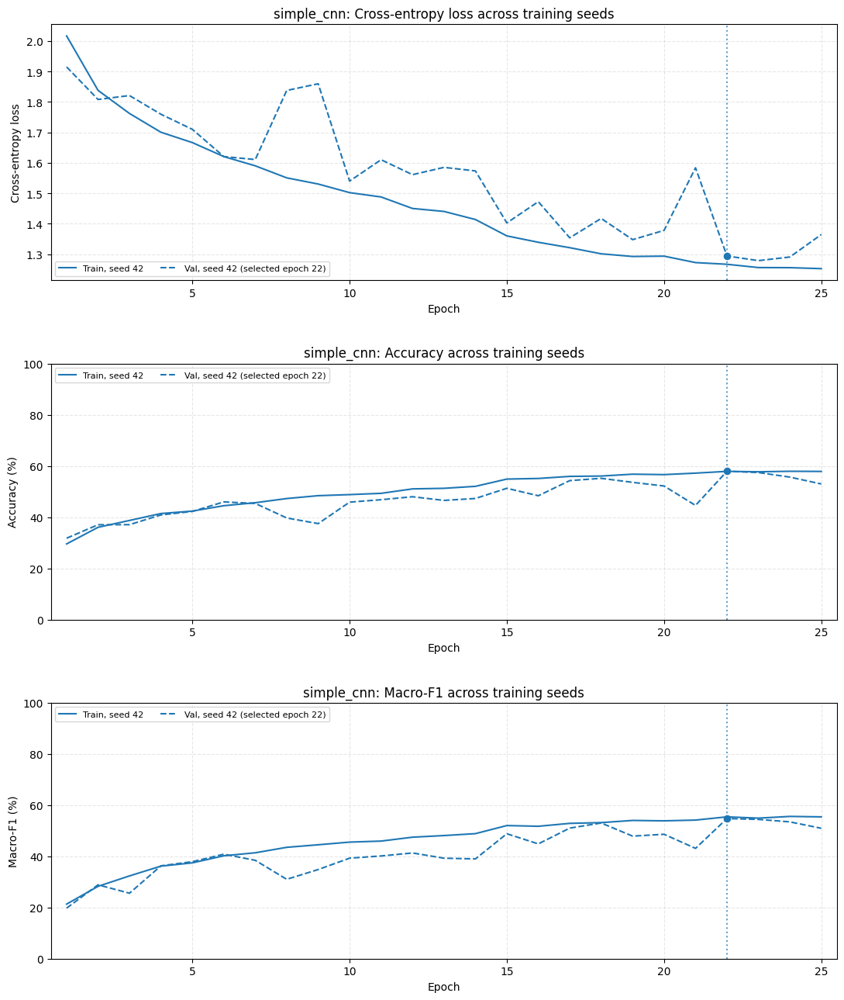

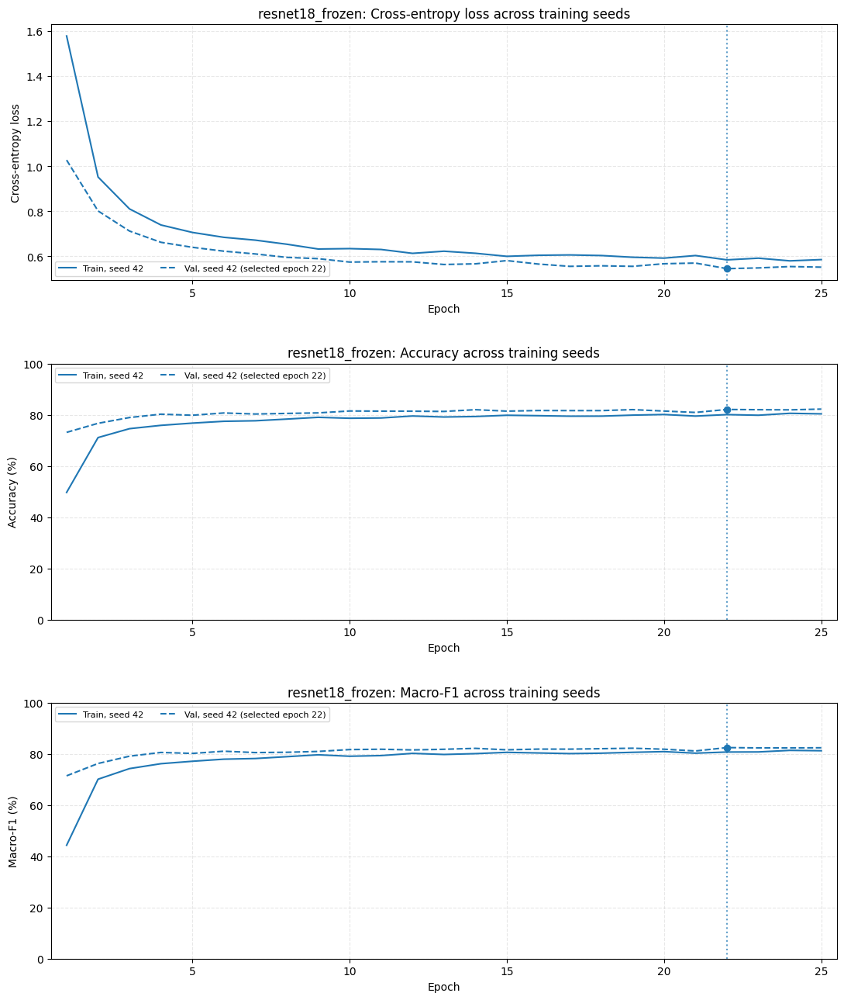

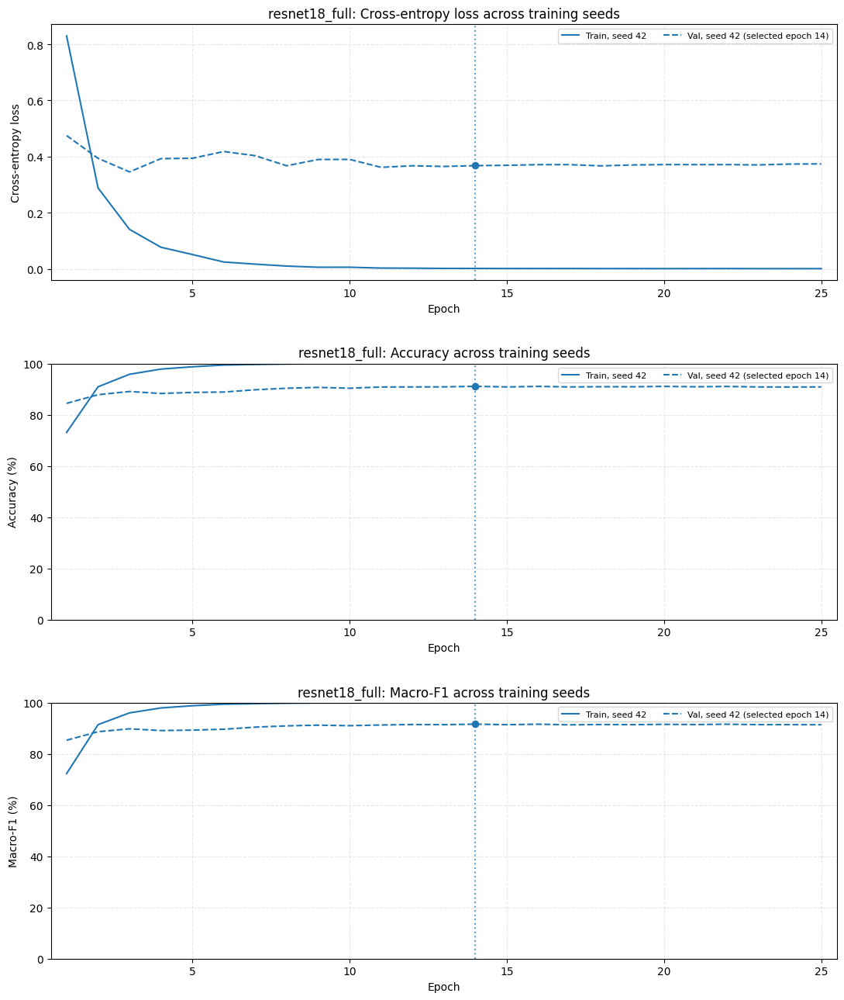

,model,run_name,seed,epochs_run,selected_epoch,selected_val_loss,selected_val_accuracy,selected_val_macro_f1,train_minus_val_f1_pp,last_val_loss_minus_min,training_time_minutes,mean_epoch_seconds
0,simple_cnn,simple_cnn_seed42,42,25,22,1.2942,0.5791,0.5474,0.6645,0.0857,48.3073,115.9376
1,resnet18_frozen,resnet18_frozen_seed42,42,25,22,0.5451,0.8205,0.8247,-1.7380,0.0067,48.6888,116.8532
2,resnet18_full,resnet18_full_seed42,42,25,14,0.3680,0.9108,0.9162,8.3753,0.0285,59.4706,142.7295


In [ ]:
single_training_summary = training_behavior(
	single_seed_results,output_prefix=single_prefix,save=SAVE_REPORTS,
)

Recomputing test metrics: simple_cnn_seed42
Benchmarking inference: simple_cnn_seed42 | Device: cuda
Recomputing test metrics: resnet18_frozen_seed42
Benchmarking inference: resnet18_frozen_seed42 | Device: cuda
Recomputing test metrics: resnet18_full_seed42
Benchmarking inference: resnet18_full_seed42 | Device: cuda


,model,run_name,seed,selected_epoch,epochs_run,image_size,total_parameters,trainable_parameters,test_loss,test_accuracy,...,test_macro_recall,test_macro_f1,test_metrics_source,training_time_minutes,mean_epoch_seconds,inference_time_ms_per_image,inference_batch_size,inference_device,inference_hardware,training_hardware
0,simple_cnn,simple_cnn_seed42,42,22,25,256,99339,99339,1.2224,0.6014,...,0.5674,0.5665,recomputed,48.3073,115.9376,0.6442,1,cuda,Tesla T4,Tesla T4
1,resnet18_frozen,resnet18_frozen_seed42,42,22,25,256,11182155,5643,0.4962,0.8440,...,0.8504,0.8508,recomputed,48.6888,116.8532,2.2850,1,cuda,Tesla T4,Tesla T4
2,resnet18_full,resnet18_full_seed42,42,14,25,256,11182155,11182155,0.3098,0.9126,...,0.9167,0.9159,recomputed,59.4706,142.7295,2.9610,1,cuda,Tesla T4,Tesla T4


,model,n_runs,std_ddof,total_parameters,trainable_parameters,test_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_loss,training_time_minutes,mean_epoch_seconds,inference_time_ms_per_image
0,simple_cnn,1,1,99339,99339,0.5665,0.6014,0.6109,0.5674,1.2224,48.3073,115.9376,0.6442
1,resnet18_frozen,1,1,11182155,5643,0.8508,0.8440,0.8533,0.8504,0.4962,48.6888,116.8532,2.2850
2,resnet18_full,1,1,11182155,11182155,0.9159,0.9126,0.9155,0.9167,0.3098,59.4706,142.7295,2.9610


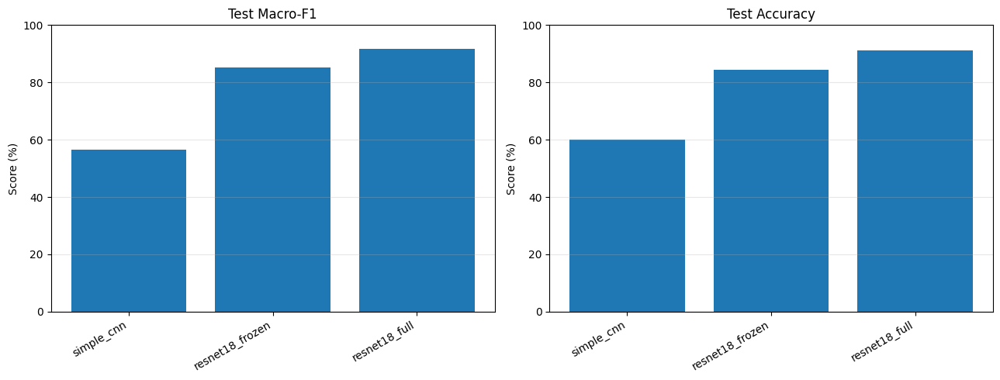

Training time includes validation and excludes checkpoint/CSV writes.
Inference: FP32 forward only, synthetic input, batch size 1; no data loading or transfers.
SD uses ddof=1 across runs, not across benchmark repetitions.
Recomputed results update this session; original per-run evaluation files are preserved.


In [ ]:
single_runs, single_summary = quantitative_results(
	single_seed_results,batch_size=REPORT_BATCH_SIZE,warmup=BENCHMARK_WARMUP,
	repeats=BENCHMARK_REPEATS,recompute_test=RECOMPUTE_TEST,
	output_prefix=single_prefix,save=SAVE_REPORTS,
)


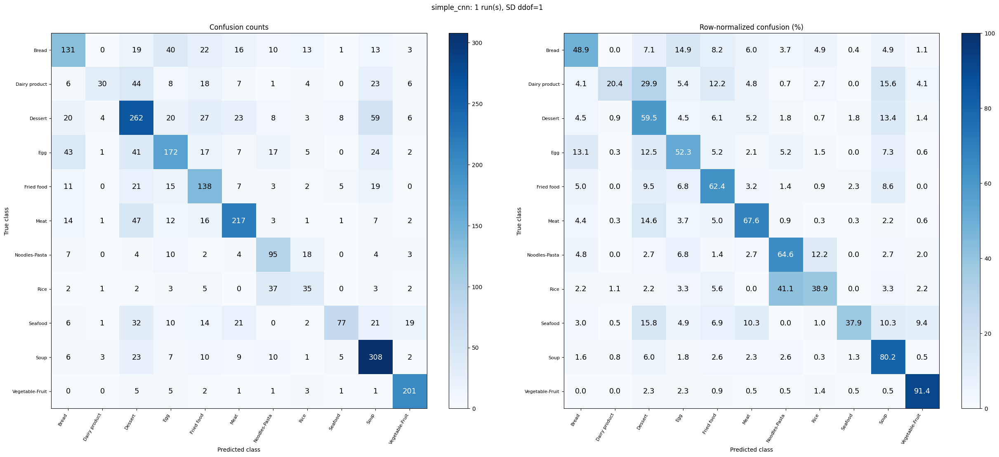

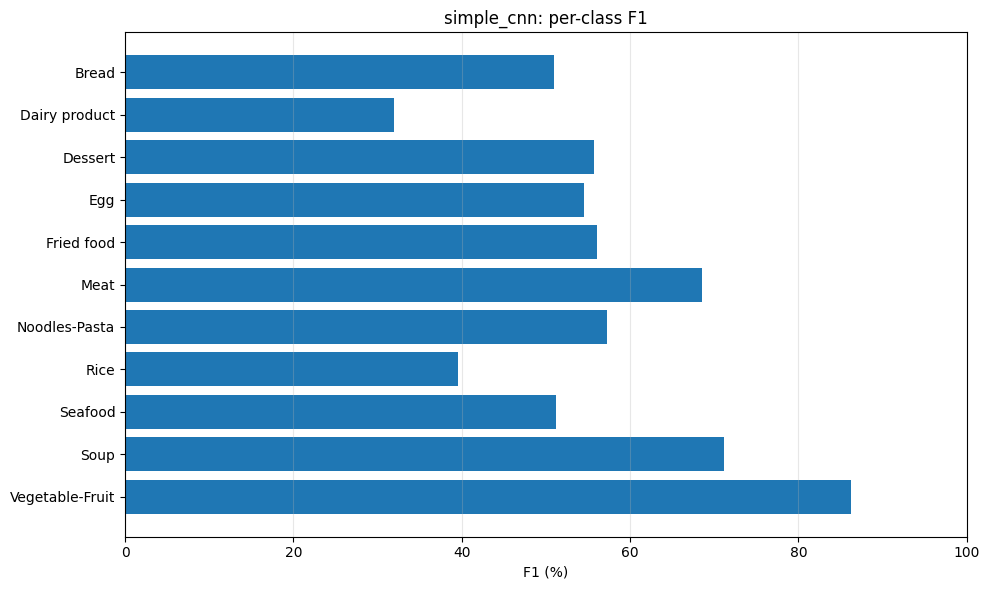


Model: simple_cnn | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,131,0,19,40,22,16,10,13,1,13,3
Dairy product,6,30,44,8,18,7,1,4,0,23,6
Dessert,20,4,262,20,27,23,8,3,8,59,6
Egg,43,1,41,172,17,7,17,5,0,24,2
Fried food,11,0,21,15,138,7,3,2,5,19,0
Meat,14,1,47,12,16,217,3,1,1,7,2
Noodles-Pasta,7,0,4,10,2,4,95,18,0,4,3
Rice,2,1,2,3,5,0,37,35,0,3,2
Seafood,6,1,32,10,14,21,0,2,77,21,19


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,48.9%,0.0%,7.1%,14.9%,8.2%,6.0%,3.7%,4.9%,0.4%,4.9%,1.1%
Dairy product,4.1%,20.4%,29.9%,5.4%,12.2%,4.8%,0.7%,2.7%,0.0%,15.6%,4.1%
Dessert,4.5%,0.9%,59.5%,4.5%,6.1%,5.2%,1.8%,0.7%,1.8%,13.4%,1.4%
Egg,13.1%,0.3%,12.5%,52.3%,5.2%,2.1%,5.2%,1.5%,0.0%,7.3%,0.6%
Fried food,5.0%,0.0%,9.5%,6.8%,62.4%,3.2%,1.4%,0.9%,2.3%,8.6%,0.0%
Meat,4.4%,0.3%,14.6%,3.7%,5.0%,67.6%,0.9%,0.3%,0.3%,2.2%,0.6%
Noodles-Pasta,4.8%,0.0%,2.7%,6.8%,1.4%,2.7%,64.6%,12.2%,0.0%,2.7%,2.0%
Rice,2.2%,1.1%,2.2%,3.3%,5.6%,0.0%,41.1%,38.9%,0.0%,3.3%,2.2%
Seafood,3.0%,0.5%,15.8%,4.9%,6.9%,10.3%,0.0%,1.0%,37.9%,10.3%,9.4%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.9090,0.5325,0.4888,0.5097,268
Dairy product,0.9538,0.7317,0.2041,0.3191,147
Dessert,0.8498,0.5240,0.5955,0.5574,440
Egg,0.8964,0.5695,0.5228,0.5452,329
Fried food,0.9220,0.5092,0.6244,0.5610,221
Meat,0.9282,0.6955,0.6760,0.6856,321
Noodles-Pasta,0.9487,0.5135,0.6463,0.5723,147
Rice,0.9614,0.4023,0.3889,0.3955,90
Seafood,0.9469,0.7857,0.3793,0.5116,203


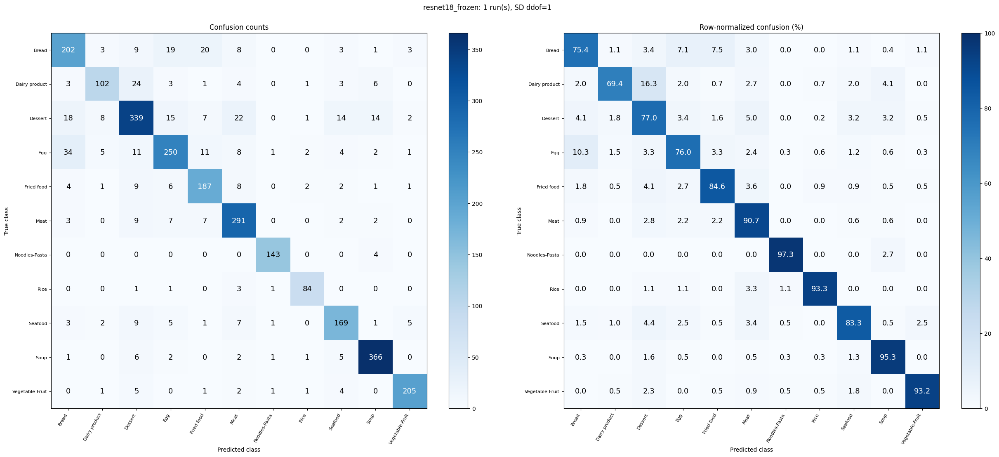

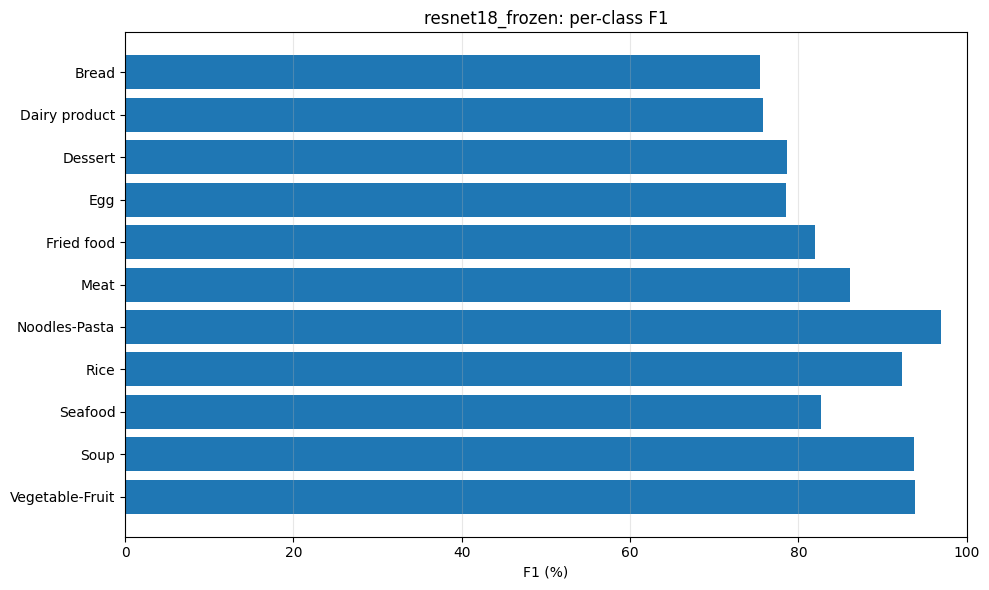


Model: resnet18_frozen | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,202,3,9,19,20,8,0,0,3,1,3
Dairy product,3,102,24,3,1,4,0,1,3,6,0
Dessert,18,8,339,15,7,22,0,1,14,14,2
Egg,34,5,11,250,11,8,1,2,4,2,1
Fried food,4,1,9,6,187,8,0,2,2,1,1
Meat,3,0,9,7,7,291,0,0,2,2,0
Noodles-Pasta,0,0,0,0,0,0,143,0,0,4,0
Rice,0,0,1,1,0,3,1,84,0,0,0
Seafood,3,2,9,5,1,7,1,0,169,1,5


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,75.4%,1.1%,3.4%,7.1%,7.5%,3.0%,0.0%,0.0%,1.1%,0.4%,1.1%
Dairy product,2.0%,69.4%,16.3%,2.0%,0.7%,2.7%,0.0%,0.7%,2.0%,4.1%,0.0%
Dessert,4.1%,1.8%,77.0%,3.4%,1.6%,5.0%,0.0%,0.2%,3.2%,3.2%,0.5%
Egg,10.3%,1.5%,3.3%,76.0%,3.3%,2.4%,0.3%,0.6%,1.2%,0.6%,0.3%
Fried food,1.8%,0.5%,4.1%,2.7%,84.6%,3.6%,0.0%,0.9%,0.9%,0.5%,0.5%
Meat,0.9%,0.0%,2.8%,2.2%,2.2%,90.7%,0.0%,0.0%,0.6%,0.6%,0.0%
Noodles-Pasta,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,97.3%,0.0%,0.0%,2.7%,0.0%
Rice,0.0%,0.0%,1.1%,1.1%,0.0%,3.3%,1.1%,93.3%,0.0%,0.0%,0.0%
Seafood,1.5%,1.0%,4.4%,2.5%,0.5%,3.4%,0.5%,0.0%,83.3%,0.5%,2.5%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.9523,0.7537,0.7537,0.7537,268
Dairy product,0.9765,0.8361,0.6939,0.7584,147
Dessert,0.9336,0.8033,0.7705,0.7865,440
Egg,0.9505,0.8117,0.7599,0.7849,329
Fried food,0.9704,0.7957,0.8462,0.8202,221
Meat,0.9661,0.8197,0.9065,0.8609,321
Noodles-Pasta,0.9968,0.9662,0.9728,0.9695,147
Rice,0.9949,0.9130,0.9333,0.9231,90
Seafood,0.9744,0.8204,0.8325,0.8264,203


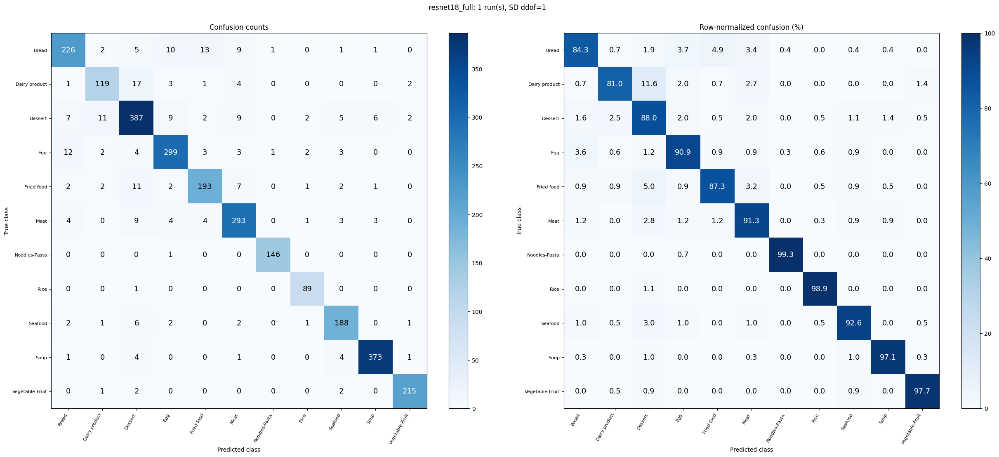

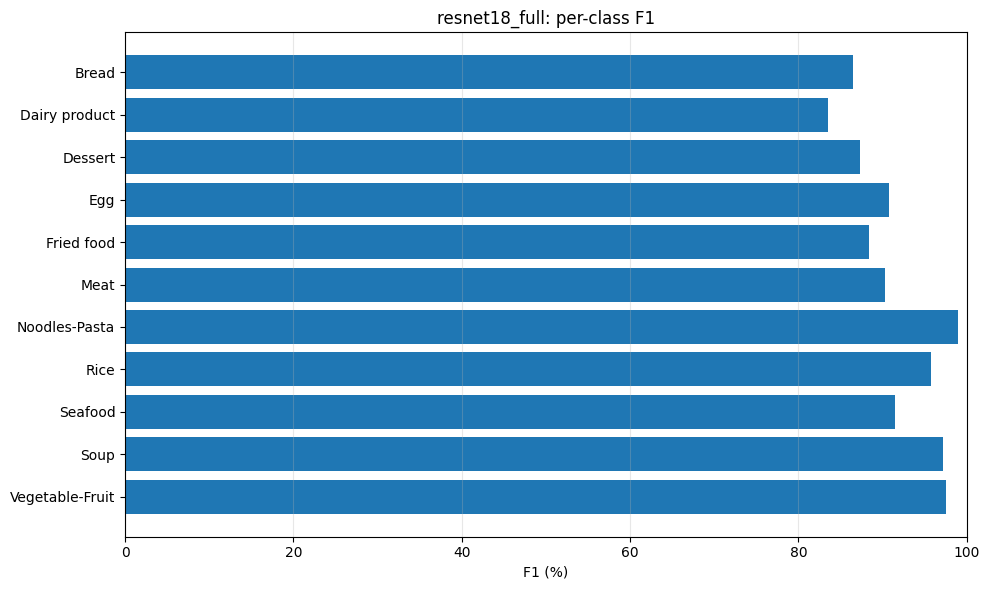


Model: resnet18_full | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,226,2,5,10,13,9,1,0,1,1,0
Dairy product,1,119,17,3,1,4,0,0,0,0,2
Dessert,7,11,387,9,2,9,0,2,5,6,2
Egg,12,2,4,299,3,3,1,2,3,0,0
Fried food,2,2,11,2,193,7,0,1,2,1,0
Meat,4,0,9,4,4,293,0,1,3,3,0
Noodles-Pasta,0,0,0,1,0,0,146,0,0,0,0
Rice,0,0,1,0,0,0,0,89,0,0,0
Seafood,2,1,6,2,0,2,0,1,188,0,1


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,84.3%,0.7%,1.9%,3.7%,4.9%,3.4%,0.4%,0.0%,0.4%,0.4%,0.0%
Dairy product,0.7%,81.0%,11.6%,2.0%,0.7%,2.7%,0.0%,0.0%,0.0%,0.0%,1.4%
Dessert,1.6%,2.5%,88.0%,2.0%,0.5%,2.0%,0.0%,0.5%,1.1%,1.4%,0.5%
Egg,3.6%,0.6%,1.2%,90.9%,0.9%,0.9%,0.3%,0.6%,0.9%,0.0%,0.0%
Fried food,0.9%,0.9%,5.0%,0.9%,87.3%,3.2%,0.0%,0.5%,0.9%,0.5%,0.0%
Meat,1.2%,0.0%,2.8%,1.2%,1.2%,91.3%,0.0%,0.3%,0.9%,0.9%,0.0%
Noodles-Pasta,0.0%,0.0%,0.0%,0.7%,0.0%,0.0%,99.3%,0.0%,0.0%,0.0%,0.0%
Rice,0.0%,0.0%,1.1%,0.0%,0.0%,0.0%,0.0%,98.9%,0.0%,0.0%,0.0%
Seafood,1.0%,0.5%,3.0%,1.0%,0.0%,1.0%,0.0%,0.5%,92.6%,0.0%,0.5%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.9744,0.8863,0.8433,0.8642,268
Dairy product,0.9830,0.8623,0.8095,0.8351,147
Dessert,0.9596,0.8677,0.8795,0.8736,440
Egg,0.9780,0.9061,0.9088,0.9074,329
Fried food,0.9816,0.8935,0.8733,0.8833,221
Meat,0.9773,0.8933,0.9128,0.9029,321
Noodles-Pasta,0.9989,0.9865,0.9932,0.9898,147
Rice,0.9971,0.9271,0.9889,0.9570,90
Seafood,0.9874,0.9038,0.9261,0.9148,203


In [ ]:
single_class_outputs = class_results(
	single_seed_results,output_prefix=single_prefix,save=SAVE_REPORTS,
)


In [ ]:
def qualitative_results(
	result, n=8, batch_size=32,
	seed=42, device=None, save=True,
):
	assert n > 0

	model, checkpoint, _, run_device = restore_report_model(
		result, device,
	)

	predictions = result['predictions'].reset_index(drop=True)
	if ARTIFACT_SOURCE == 'github':
		# The published CSV may contain paths from a different Colab runtime.
		test_folder = SPLIT_DIRS['test']
		test_root = DATA_ROOT / test_folder
		local_paths = {
			Path(path).relative_to(test_root).as_posix(): path
			for path in test_df['path']
		}
		def relative_test_path(path):
			parts = Path(path).parts
			if test_folder in parts:
				parts = parts[parts.index(test_folder) + 1:]
			return Path(*parts).as_posix()

		paths = predictions['path'].map(relative_test_path).map(local_paths)
		if paths.isna().any():
			raise FileNotFoundError('A prediction CSV path does not match the current Food-11 test split.')
		predictions['path'] = paths

	frame = predictions[['path', 'true_label']].rename(
		columns={'true_label': 'label'}
	)

	loader = DataLoader(
		FoodDataset(frame, eval_transform),
		batch_size=batch_size,
		shuffle=False,
		num_workers=0,
		generator=torch.Generator().manual_seed(seed),
	)

	probabilities = []

	with torch.inference_mode():
		for images, _ in loader:
			logits = model(
				images.to(run_device, dtype=torch.float32)
			)
			probabilities.append(
				torch.softmax(logits, dim=1).cpu().numpy()
			)

	probabilities = np.concatenate(probabilities)
	y_true = predictions['true_label'].to_numpy(dtype=int)
	y_pred = probabilities.argmax(axis=1)

	if not np.array_equal(
		y_pred,
		predictions['predicted_label'].to_numpy(dtype=int),
	):
		raise ValueError(
			'Checkpoint predictions differ from saved results; '
			'verify checkpoint/transforms.'
		)

	top_two = np.argsort(
		-probabilities, axis=1, kind='stable',
	)[:, :2]

	top_scores = np.take_along_axis(
		probabilities, top_two, axis=1,
	)

	margin = top_scores[:, 0] - top_scores[:, 1]
	correct = np.flatnonzero(y_pred == y_true)
	wrong = np.flatnonzero(y_pred != y_true)

	difficult = correct[
		np.argsort(margin[correct], kind='stable')[:n]
	]
	regular_pool = np.setdiff1d(correct, difficult)
	rng = np.random.default_rng(seed)

	groups = {
		'correct': rng.choice(
			regular_pool,
			min(n, len(regular_pool)),
			replace=False,
		),
		'difficult_correct_candidates': difficult,
		'failures': rng.choice(
			wrong,
			min(n, len(wrong)),
			replace=False,
		),
	}

	scored = predictions.copy()
	scored['top1_score'] = top_scores[:, 0]
	scored['top2_class'] = [
		CLASSES[i] for i in top_two[:, 1]
	]
	scored['top2_score'] = top_scores[:, 1]
	scored['top1_top2_gap'] = margin
	scored['true_class_score'] = probabilities[
		np.arange(len(y_true)), y_true
	]
	scored['correct'] = y_pred == y_true

	selected_tables = []

	for kind, indices in groups.items():
		if len(indices) == 0:
			print('No examples:', kind)
			continue

		selected_tables.append(
			scored.iloc[indices].assign(selection=kind)
		)

		ncols = min(4, len(indices))
		nrows = math.ceil(len(indices) / ncols)

		fig, axes = plt.subplots(
			nrows,
			ncols,
			figsize=(3.8 * ncols, 4 * nrows),
			squeeze=False,
		)

		for ax in axes.ravel():
			ax.axis('off')

		for ax, index in zip(axes.ravel(), indices):
			row = scored.iloc[index]

			with Image.open(row['path']) as im:
				ax.imshow(im.convert('RGB'))

			if kind == 'difficult_correct_candidates':
				text = (
					f'True: {CLASSES[y_true[index]]}\n'
					f'Top-1: {CLASSES[y_pred[index]]} '
					f'({100 * top_scores[index, 0]:.1f}%)\n'
					f'Top-2: {row["top2_class"]} '
					f'({100 * row["top2_score"]:.1f}%)'
				)
			else:
				text = (
					f'True: {CLASSES[y_true[index]]} '
					f'({100 * row["true_class_score"]:.1f}%)\n'
					f'Pred: {CLASSES[y_pred[index]]} '
					f'({100 * row["top1_score"]:.1f}%)'
				)

			ax.set_title(
				text,
				fontsize=9,
				color=(
					'darkgreen'
					if row['correct']
					else 'firebrick'
				),
			)

		fig.suptitle(
			f'{result["run_name"]}: {kind.replace("_", " ")}'
		)
		fig.tight_layout(rect=[0, 0, 1, 0.95])

		finish_report_figure(
			fig,
			f'{result["run_name"]}_{kind}.png',
			save,
		)

	selected = pd.concat(selected_tables, ignore_index=True)

	if save:
		scored.to_csv(
			TAB_DIR / f'{result["run_name"]}_scored_predictions.csv',
			index=False,
		)
		selected.to_csv(
			TAB_DIR / f'{result["run_name"]}_qualitative_examples.csv',
			index=False,
		)

	print('Difficult candidates use the smallest top-1/top-2 gaps among correct predictions.')
	print('Softmax scores are not calibrated probabilities; inspect the examples manually.')

	del model, checkpoint

	return scored, selected



Run: simple_cnn_seed42


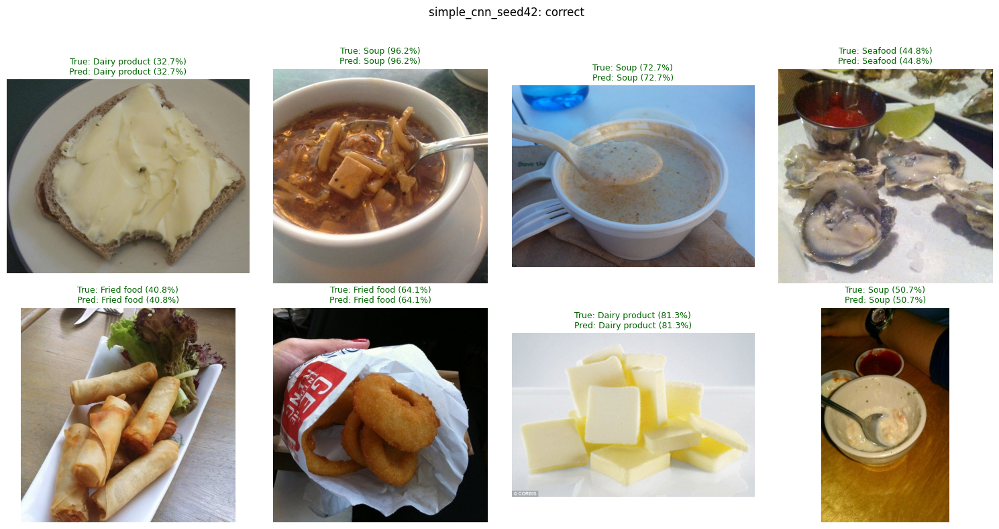

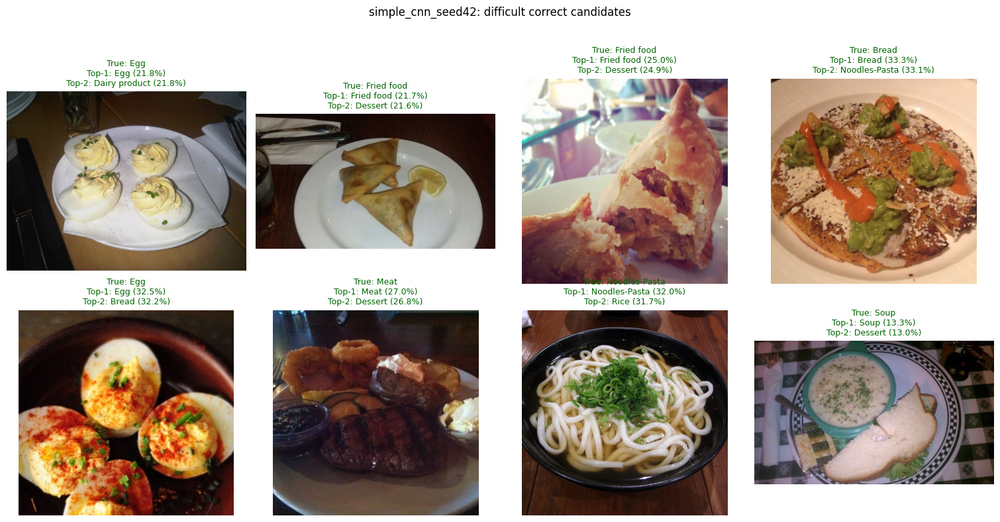

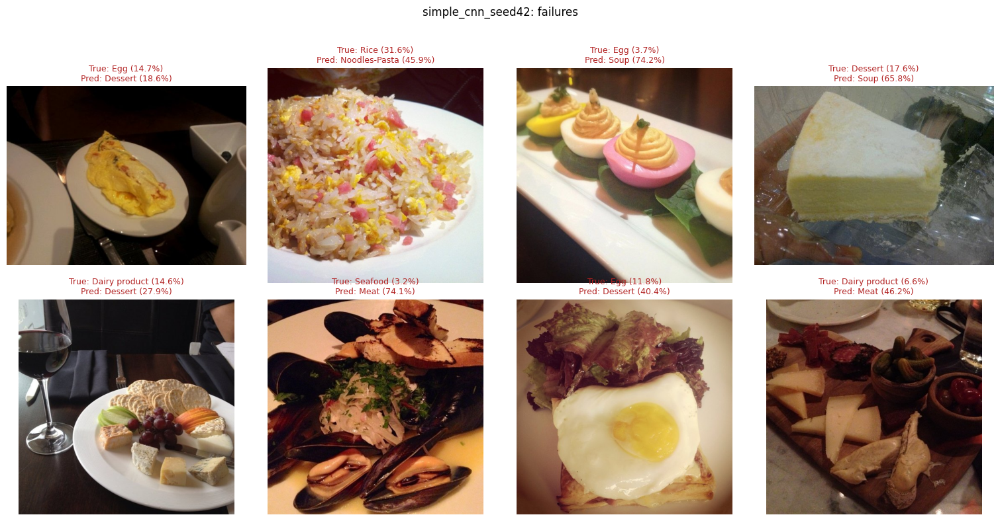

Difficult candidates use the smallest top-1/top-2 gaps among correct predictions.
Softmax scores are not calibrated probabilities; inspect the examples manually.

Run: resnet18_frozen_seed42


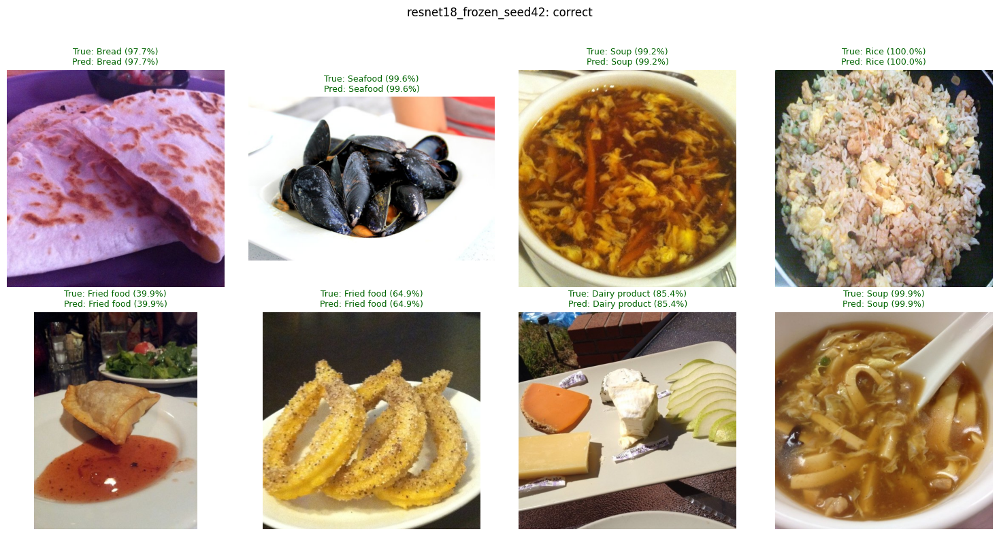

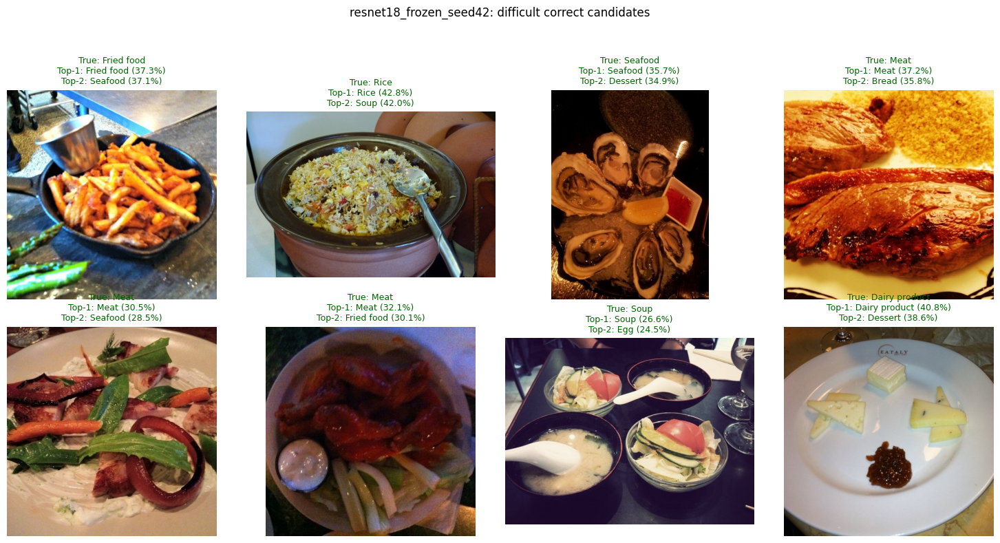

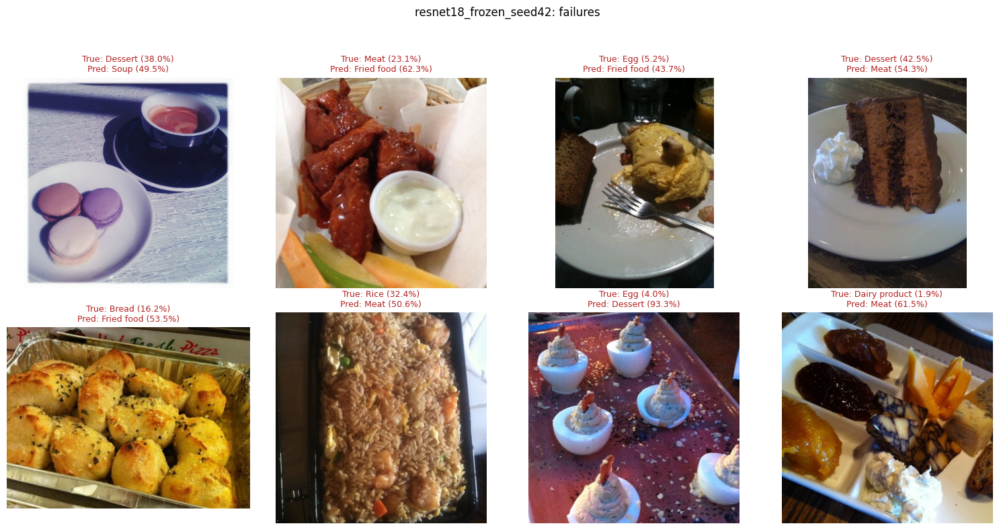

Difficult candidates use the smallest top-1/top-2 gaps among correct predictions.
Softmax scores are not calibrated probabilities; inspect the examples manually.

Run: resnet18_full_seed42


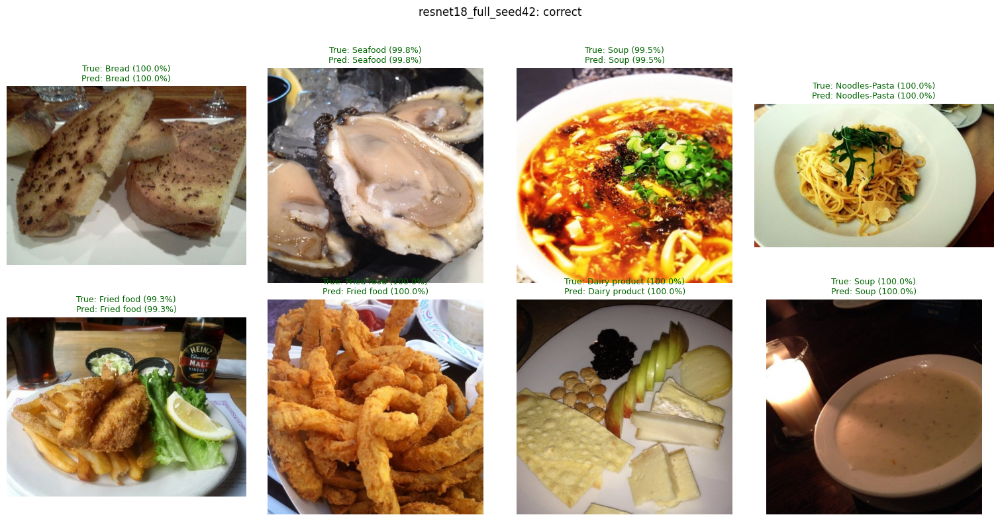

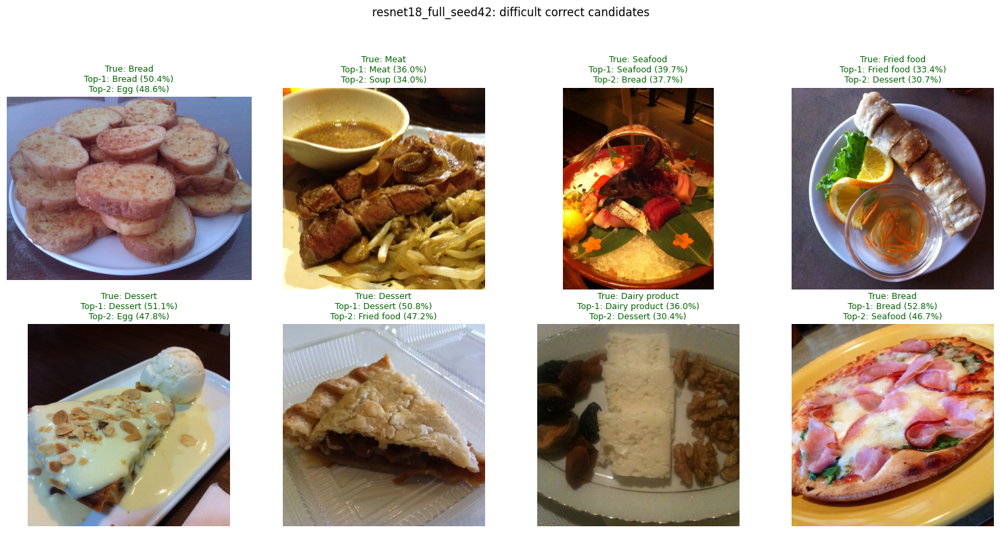

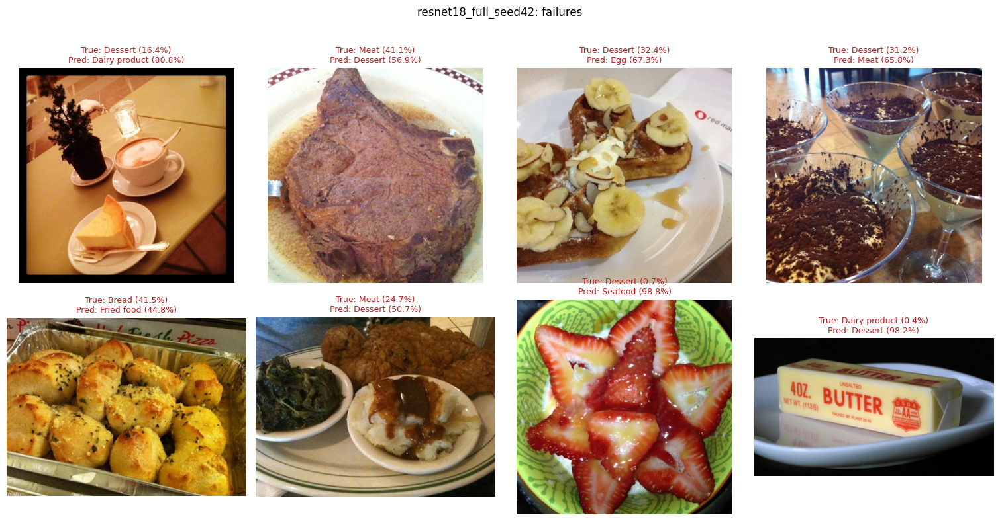

Difficult candidates use the smallest top-1/top-2 gaps among correct predictions.
Softmax scores are not calibrated probabilities; inspect the examples manually.


In [ ]:
qualitative_outputs = {}
for result in single_seed_results:
	print('\nRun:',result['run_name'])
	scored,selected = qualitative_results(
		result,n=8,batch_size=REPORT_BATCH_SIZE,
		seed=SINGLE_REPORT_SEED,save=SAVE_REPORTS,
	)
	qualitative_outputs[result['run_name']] = {
		'scored_predictions':scored,'selected_examples':selected,
	}


# **Three Seed**

In [ ]:
REPORT_SEEDS = [42,43,44]
assert len(REPORT_SEEDS)==len(set(REPORT_SEEDS))==3
multi_prefix = 'three_seeds_'+'_'.join(map(str,REPORT_SEEDS))
multi_seed_results = [
	load_saved_result(f'{name}_seed{seed}')
	for name in MODEL_NAMES for seed in REPORT_SEEDS
]
group_report_results(multi_seed_results,expected_seeds=REPORT_SEEDS)
print('Loaded runs:',len(multi_seed_results))


Loaded: simple_cnn_seed42
Loaded: simple_cnn_seed43
Loaded: simple_cnn_seed44
Loaded: resnet18_frozen_seed42
Loaded: resnet18_frozen_seed43
Loaded: resnet18_frozen_seed44
Loaded: resnet18_full_seed42
Loaded: resnet18_full_seed43
Loaded: resnet18_full_seed44
Loaded runs: 9


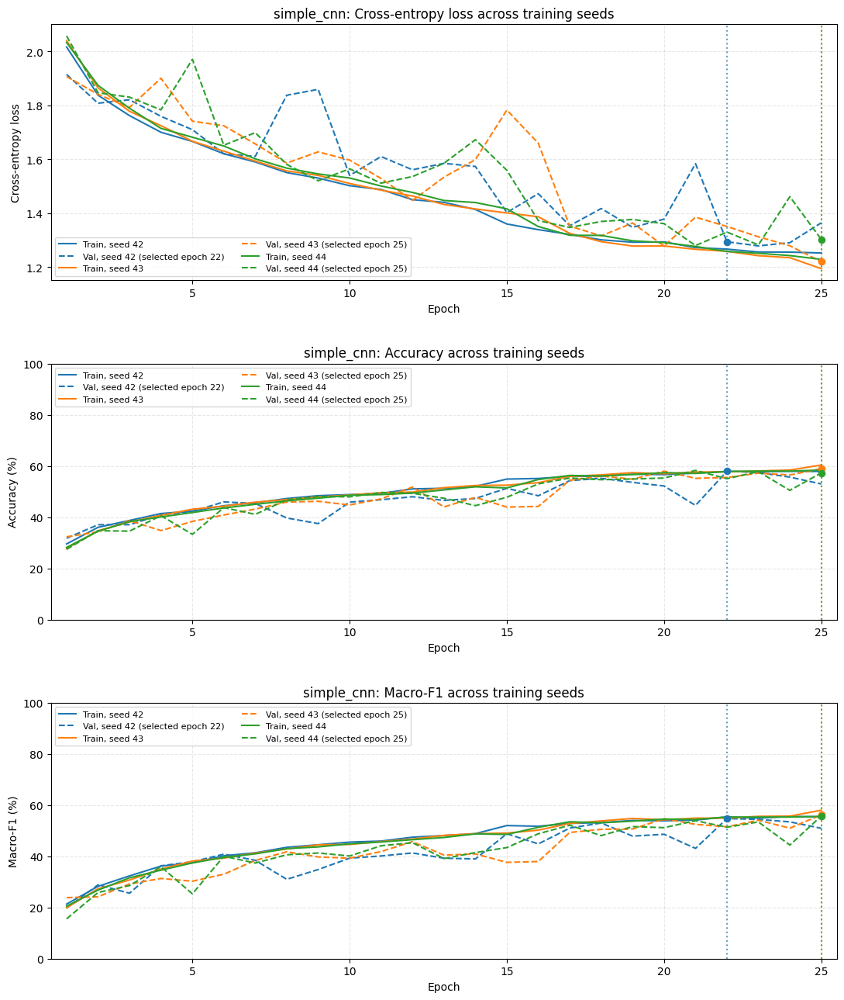

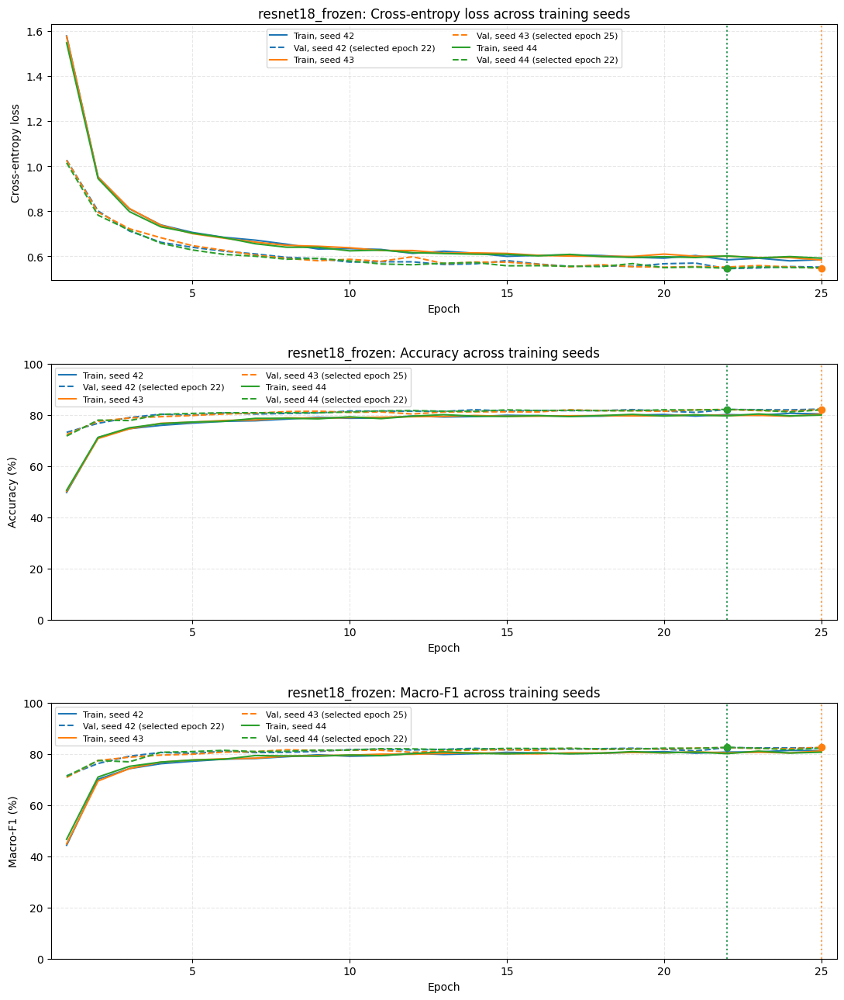

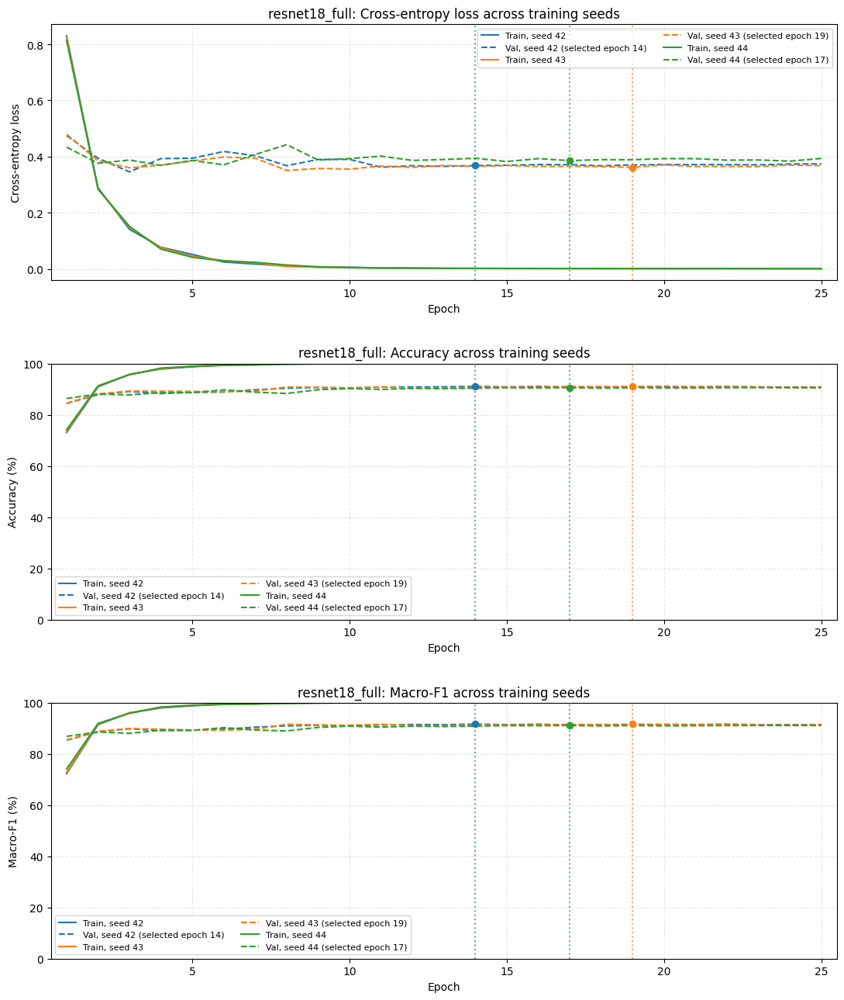

,model,run_name,seed,epochs_run,selected_epoch,selected_val_loss,selected_val_accuracy,selected_val_macro_f1,train_minus_val_f1_pp,last_val_loss_minus_min,training_time_minutes,mean_epoch_seconds
0,simple_cnn,simple_cnn_seed42,42,25,22,1.2942,0.5791,0.5474,0.6645,0.0857,48.3073,115.9376
1,simple_cnn,simple_cnn_seed43,43,25,25,1.2200,0.5889,0.5622,1.7868,0.0000,51.6491,123.9578
2,simple_cnn,simple_cnn_seed44,44,25,25,1.3031,0.5725,0.5574,-0.1608,0.0228,48.5166,116.4398
3,resnet18_frozen,resnet18_frozen_seed42,42,25,22,0.5451,0.8205,0.8247,-1.7380,0.0067,48.6888,116.8532
4,resnet18_frozen,resnet18_frozen_seed43,43,25,25,0.5465,0.8202,0.8254,-1.3936,0.0000,51.3696,123.2871
5,resnet18_frozen,resnet18_frozen_seed44,44,25,22,0.5470,0.8207,0.8254,-2.4476,0.0020,48.4548,116.2915
6,resnet18_full,resnet18_full_seed42,42,25,14,0.3680,0.9108,0.9162,8.3753,0.0285,59.4706,142.7295
7,resnet18_full,resnet18_full_seed43,43,25,19,0.3615,0.9099,0.9165,8.3398,0.0172,61.7002,148.0805
8,resnet18_full,resnet18_full_seed44,44,25,17,0.3856,0.9058,0.9112,8.8777,0.0244,59.8063,143.5352


In [ ]:
multi_training_summary = training_behavior(
	multi_seed_results,output_prefix=multi_prefix,save=SAVE_REPORTS,
)


Recomputing test metrics: simple_cnn_seed42
Benchmarking inference: simple_cnn_seed42 | Device: cuda
Recomputing test metrics: simple_cnn_seed43
Benchmarking inference: simple_cnn_seed43 | Device: cuda
Recomputing test metrics: simple_cnn_seed44
Benchmarking inference: simple_cnn_seed44 | Device: cuda
Recomputing test metrics: resnet18_frozen_seed42
Benchmarking inference: resnet18_frozen_seed42 | Device: cuda
Recomputing test metrics: resnet18_frozen_seed43
Benchmarking inference: resnet18_frozen_seed43 | Device: cuda
Recomputing test metrics: resnet18_frozen_seed44
Benchmarking inference: resnet18_frozen_seed44 | Device: cuda
Recomputing test metrics: resnet18_full_seed42
Benchmarking inference: resnet18_full_seed42 | Device: cuda
Recomputing test metrics: resnet18_full_seed43
Benchmarking inference: resnet18_full_seed43 | Device: cuda
Recomputing test metrics: resnet18_full_seed44
Benchmarking inference: resnet18_full_seed44 | Device: cuda


,model,run_name,seed,selected_epoch,epochs_run,image_size,total_parameters,trainable_parameters,test_loss,test_accuracy,...,test_macro_recall,test_macro_f1,test_metrics_source,training_time_minutes,mean_epoch_seconds,inference_time_ms_per_image,inference_batch_size,inference_device,inference_hardware,training_hardware
0,simple_cnn,simple_cnn_seed42,42,22,25,256,99339,99339,1.2224,0.6014,...,0.5674,0.5665,recomputed,48.3073,115.9376,0.8580,1,cuda,Tesla T4,Tesla T4
1,simple_cnn,simple_cnn_seed43,43,25,25,256,99339,99339,1.1745,0.6152,...,0.5776,0.5830,recomputed,51.6491,123.9578,0.6914,1,cuda,Tesla T4,Tesla T4
2,simple_cnn,simple_cnn_seed44,44,25,25,256,99339,99339,1.2211,0.5953,...,0.5718,0.5779,recomputed,48.5166,116.4398,0.6970,1,cuda,Tesla T4,Tesla T4
3,resnet18_frozen,resnet18_frozen_seed42,42,22,25,256,11182155,5643,0.4962,0.8440,...,0.8504,0.8508,recomputed,48.6888,116.8532,2.4285,1,cuda,Tesla T4,Tesla T4
4,resnet18_frozen,resnet18_frozen_seed43,43,25,25,256,11182155,5643,0.4896,0.8487,...,0.8542,0.8542,recomputed,51.3696,123.2871,3.2666,1,cuda,Tesla T4,Tesla T4
5,resnet18_frozen,resnet18_frozen_seed44,44,22,25,256,11182155,5643,0.4955,0.8458,...,0.8524,0.8527,recomputed,48.4548,116.2915,2.4273,1,cuda,Tesla T4,Tesla T4
6,resnet18_full,resnet18_full_seed42,42,14,25,256,11182155,11182155,0.3098,0.9126,...,0.9167,0.9159,recomputed,59.4706,142.7295,2.4205,1,cuda,Tesla T4,Tesla T4
7,resnet18_full,resnet18_full_seed43,43,19,25,256,11182155,11182155,0.3125,0.9184,...,0.9217,0.9209,recomputed,61.7002,148.0805,2.3990,1,cuda,Tesla T4,Tesla T4
8,resnet18_full,resnet18_full_seed44,44,17,25,256,11182155,11182155,0.3367,0.9101,...,0.9139,0.9133,recomputed,59.8063,143.5352,2.4157,1,cuda,Tesla T4,Tesla T4


,model,n_runs,std_ddof,total_parameters,trainable_parameters,test_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_loss,training_time_minutes,mean_epoch_seconds,inference_time_ms_per_image
0,simple_cnn,3,1,99339,99339,0.5758 ± 0.0084,0.6040 ± 0.0102,0.6348 ± 0.0225,0.5723 ± 0.0051,1.2060 ± 0.0273,49.4910 ± 1.8719,118.7784 ± 4.4926,0.7488 ± 0.0946
1,resnet18_frozen,3,1,11182155,5643,0.8526 ± 0.0017,0.8462 ± 0.0024,0.8545 ± 0.0010,0.8523 ± 0.0019,0.4938 ± 0.0036,49.5044 ± 1.6196,118.8106 ± 3.8869,2.7075 ± 0.4842
2,resnet18_full,3,1,11182155,11182155,0.9167 ± 0.0039,0.9137 ± 0.0043,0.9165 ± 0.0037,0.9174 ± 0.0040,0.3197 ± 0.0148,60.3257 ± 1.2021,144.7817 ± 2.8851,2.4117 ± 0.0113


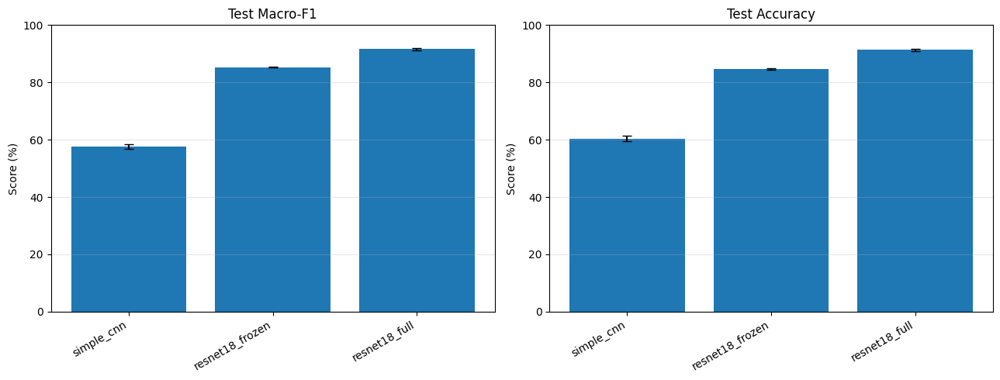

Training time includes validation and excludes checkpoint/CSV writes.
Inference: FP32 forward only, synthetic input, batch size 1; no data loading or transfers.
SD uses ddof=1 across runs, not across benchmark repetitions.
Recomputed results update this session; original per-run evaluation files are preserved.


In [ ]:
multi_seed_runs, multi_seed_summary = quantitative_results(
	multi_seed_results,batch_size=REPORT_BATCH_SIZE,warmup=BENCHMARK_WARMUP,
	repeats=BENCHMARK_REPEATS,recompute_test=RECOMPUTE_TEST,
	output_prefix=multi_prefix,save=SAVE_REPORTS,
)


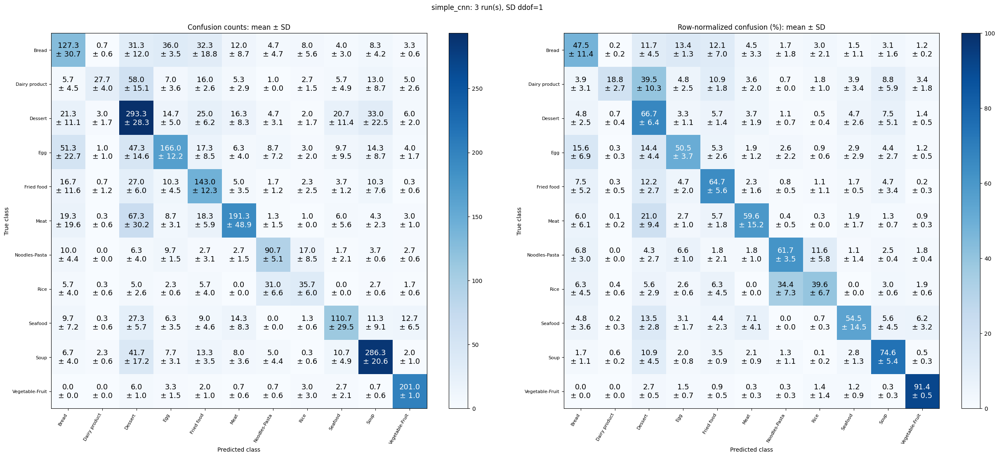

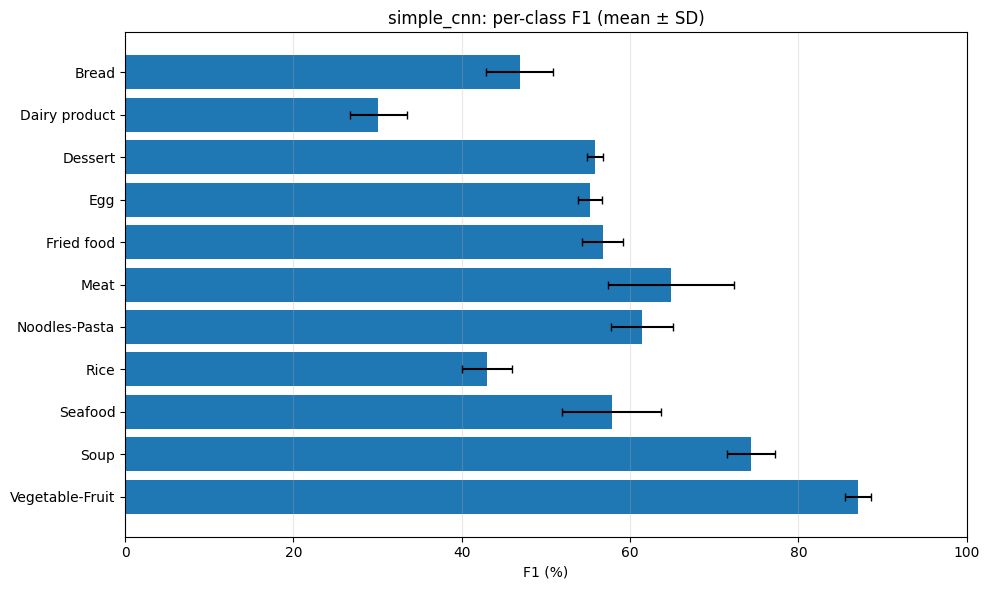


Model: simple_cnn | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,127.3 ± 30.7,0.7 ± 0.6,31.3 ± 12.0,36.0 ± 3.5,32.3 ± 18.8,12.0 ± 8.7,4.7 ± 4.7,8.0 ± 5.6,4.0 ± 3.0,8.3 ± 4.2,3.3 ± 0.6
Dairy product,5.7 ± 4.5,27.7 ± 4.0,58.0 ± 15.1,7.0 ± 3.6,16.0 ± 2.6,5.3 ± 2.9,1.0 ± 0.0,2.7 ± 1.5,5.7 ± 4.9,13.0 ± 8.7,5.0 ± 2.6
Dessert,21.3 ± 11.1,3.0 ± 1.7,293.3 ± 28.3,14.7 ± 5.0,25.0 ± 6.2,16.3 ± 8.3,4.7 ± 3.1,2.0 ± 1.7,20.7 ± 11.4,33.0 ± 22.5,6.0 ± 2.0
Egg,51.3 ± 22.7,1.0 ± 1.0,47.3 ± 14.6,166.0 ± 12.2,17.3 ± 8.5,6.3 ± 4.0,8.7 ± 7.2,3.0 ± 2.0,9.7 ± 9.5,14.3 ± 8.7,4.0 ± 1.7
Fried food,16.7 ± 11.6,0.7 ± 1.2,27.0 ± 6.0,10.3 ± 4.5,143.0 ± 12.3,5.0 ± 3.5,1.7 ± 1.2,2.3 ± 2.5,3.7 ± 1.2,10.3 ± 7.6,0.3 ± 0.6
Meat,19.3 ± 19.6,0.3 ± 0.6,67.3 ± 30.2,8.7 ± 3.1,18.3 ± 5.9,191.3 ± 48.9,1.3 ± 1.5,1.0 ± 0.0,6.0 ± 5.6,4.3 ± 2.3,3.0 ± 1.0
Noodles-Pasta,10.0 ± 4.4,0.0 ± 0.0,6.3 ± 4.0,9.7 ± 1.5,2.7 ± 3.1,2.7 ± 1.5,90.7 ± 5.1,17.0 ± 8.5,1.7 ± 2.1,3.7 ± 0.6,2.7 ± 0.6
Rice,5.7 ± 4.0,0.3 ± 0.6,5.0 ± 2.6,2.3 ± 0.6,5.7 ± 4.0,0.0 ± 0.0,31.0 ± 6.6,35.7 ± 6.0,0.0 ± 0.0,2.7 ± 0.6,1.7 ± 0.6
Seafood,9.7 ± 7.2,0.3 ± 0.6,27.3 ± 5.7,6.3 ± 3.5,9.0 ± 4.6,14.3 ± 8.3,0.0 ± 0.0,1.3 ± 0.6,110.7 ± 29.5,11.3 ± 9.1,12.7 ± 6.5


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,47.5 ± 11.4%,0.2 ± 0.2%,11.7 ± 4.5%,13.4 ± 1.3%,12.1 ± 7.0%,4.5 ± 3.3%,1.7 ± 1.8%,3.0 ± 2.1%,1.5 ± 1.1%,3.1 ± 1.6%,1.2 ± 0.2%
Dairy product,3.9 ± 3.1%,18.8 ± 2.7%,39.5 ± 10.3%,4.8 ± 2.5%,10.9 ± 1.8%,3.6 ± 2.0%,0.7 ± 0.0%,1.8 ± 1.0%,3.9 ± 3.4%,8.8 ± 5.9%,3.4 ± 1.8%
Dessert,4.8 ± 2.5%,0.7 ± 0.4%,66.7 ± 6.4%,3.3 ± 1.1%,5.7 ± 1.4%,3.7 ± 1.9%,1.1 ± 0.7%,0.5 ± 0.4%,4.7 ± 2.6%,7.5 ± 5.1%,1.4 ± 0.5%
Egg,15.6 ± 6.9%,0.3 ± 0.3%,14.4 ± 4.4%,50.5 ± 3.7%,5.3 ± 2.6%,1.9 ± 1.2%,2.6 ± 2.2%,0.9 ± 0.6%,2.9 ± 2.9%,4.4 ± 2.7%,1.2 ± 0.5%
Fried food,7.5 ± 5.2%,0.3 ± 0.5%,12.2 ± 2.7%,4.7 ± 2.0%,64.7 ± 5.6%,2.3 ± 1.6%,0.8 ± 0.5%,1.1 ± 1.1%,1.7 ± 0.5%,4.7 ± 3.4%,0.2 ± 0.3%
Meat,6.0 ± 6.1%,0.1 ± 0.2%,21.0 ± 9.4%,2.7 ± 1.0%,5.7 ± 1.8%,59.6 ± 15.2%,0.4 ± 0.5%,0.3 ± 0.0%,1.9 ± 1.7%,1.3 ± 0.7%,0.9 ± 0.3%
Noodles-Pasta,6.8 ± 3.0%,0.0 ± 0.0%,4.3 ± 2.7%,6.6 ± 1.0%,1.8 ± 2.1%,1.8 ± 1.0%,61.7 ± 3.5%,11.6 ± 5.8%,1.1 ± 1.4%,2.5 ± 0.4%,1.8 ± 0.4%
Rice,6.3 ± 4.5%,0.4 ± 0.6%,5.6 ± 2.9%,2.6 ± 0.6%,6.3 ± 4.5%,0.0 ± 0.0%,34.4 ± 7.3%,39.6 ± 6.7%,0.0 ± 0.0%,3.0 ± 0.6%,1.9 ± 0.6%
Seafood,4.8 ± 3.6%,0.2 ± 0.3%,13.5 ± 2.8%,3.1 ± 1.7%,4.4 ± 2.3%,7.1 ± 4.1%,0.0 ± 0.0%,0.7 ± 0.3%,54.5 ± 14.5%,5.6 ± 4.5%,6.2 ± 3.2%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.8964 ± 0.0219,0.4892 ± 0.0870,0.4751 ± 0.1144,0.4687 ± 0.0400,268
Dairy product,0.9538 ± 0.0007,0.7647 ± 0.0309,0.1882 ± 0.0275,0.3010 ± 0.0344,147
Dessert,0.8325 ± 0.0152,0.4839 ± 0.0352,0.6667 ± 0.0643,0.5583 ± 0.0099,440
Egg,0.9029 ± 0.0058,0.6141 ± 0.0442,0.5046 ± 0.0370,0.5522 ± 0.0143,329
Fried food,0.9207 ± 0.0139,0.5122 ± 0.0690,0.6471 ± 0.0556,0.5674 ± 0.0242,221
Meat,0.9277 ± 0.0033,0.7498 ± 0.0861,0.5961 ± 0.1522,0.6487 ± 0.0750,321
Noodles-Pasta,0.9585 ± 0.0085,0.6209 ± 0.0956,0.6168 ± 0.0349,0.6144 ± 0.0366,147
Rice,0.9657 ± 0.0066,0.5042 ± 0.1544,0.3963 ± 0.0670,0.4300 ± 0.0299,90
Seafood,0.9433 ± 0.0032,0.6591 ± 0.1097,0.5452 ± 0.1453,0.5781 ± 0.0587,203


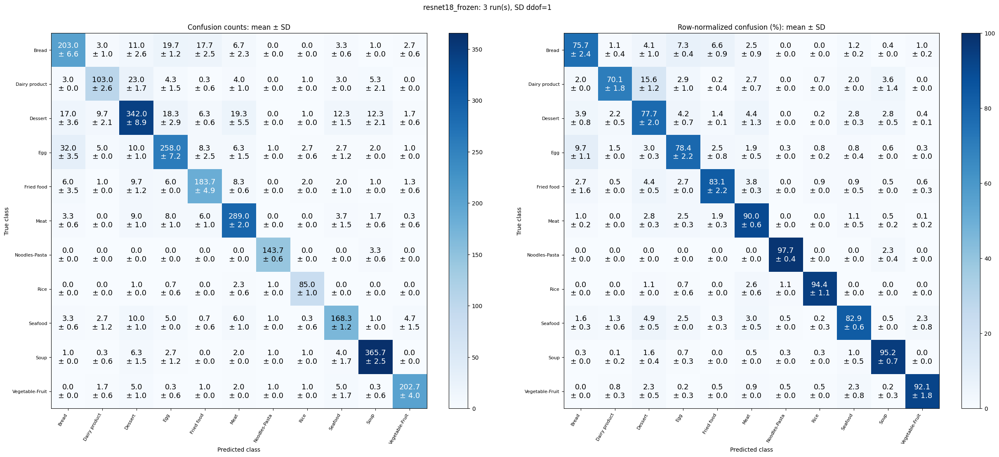

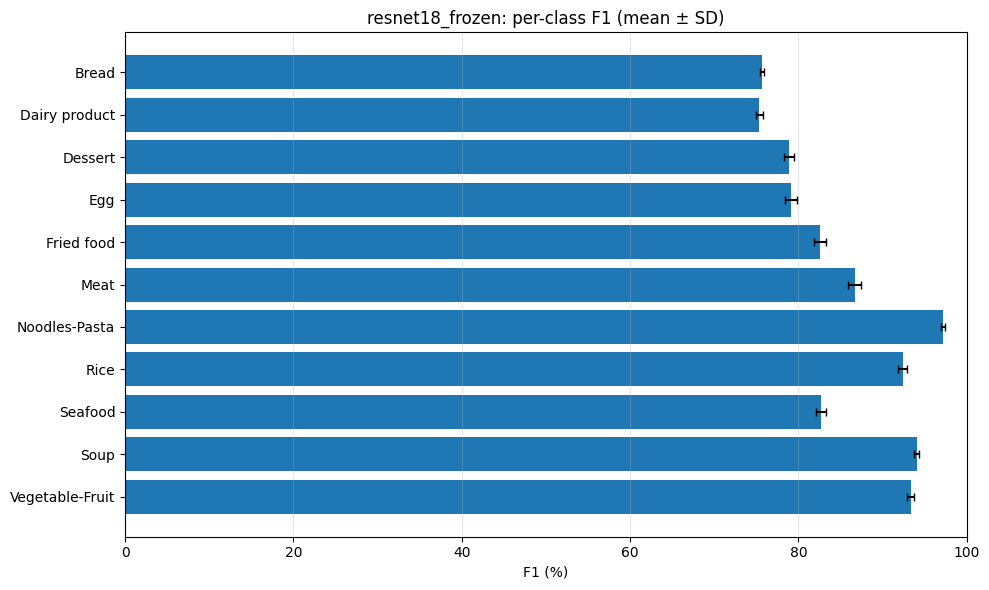


Model: resnet18_frozen | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,203.0 ± 6.6,3.0 ± 1.0,11.0 ± 2.6,19.7 ± 1.2,17.7 ± 2.5,6.7 ± 2.3,0.0 ± 0.0,0.0 ± 0.0,3.3 ± 0.6,1.0 ± 0.0,2.7 ± 0.6
Dairy product,3.0 ± 0.0,103.0 ± 2.6,23.0 ± 1.7,4.3 ± 1.5,0.3 ± 0.6,4.0 ± 1.0,0.0 ± 0.0,1.0 ± 0.0,3.0 ± 0.0,5.3 ± 2.1,0.0 ± 0.0
Dessert,17.0 ± 3.6,9.7 ± 2.1,342.0 ± 8.9,18.3 ± 2.9,6.3 ± 0.6,19.3 ± 5.5,0.0 ± 0.0,1.0 ± 0.0,12.3 ± 1.5,12.3 ± 2.1,1.7 ± 0.6
Egg,32.0 ± 3.5,5.0 ± 0.0,10.0 ± 1.0,258.0 ± 7.2,8.3 ± 2.5,6.3 ± 1.5,1.0 ± 0.0,2.7 ± 0.6,2.7 ± 1.2,2.0 ± 0.0,1.0 ± 0.0
Fried food,6.0 ± 3.5,1.0 ± 0.0,9.7 ± 1.2,6.0 ± 0.0,183.7 ± 4.9,8.3 ± 0.6,0.0 ± 0.0,2.0 ± 0.0,2.0 ± 1.0,1.0 ± 0.0,1.3 ± 0.6
Meat,3.3 ± 0.6,0.0 ± 0.0,9.0 ± 1.0,8.0 ± 1.0,6.0 ± 1.0,289.0 ± 2.0,0.0 ± 0.0,0.0 ± 0.0,3.7 ± 1.5,1.7 ± 0.6,0.3 ± 0.6
Noodles-Pasta,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,143.7 ± 0.6,0.0 ± 0.0,0.0 ± 0.0,3.3 ± 0.6,0.0 ± 0.0
Rice,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,0.7 ± 0.6,0.0 ± 0.0,2.3 ± 0.6,1.0 ± 0.0,85.0 ± 1.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
Seafood,3.3 ± 0.6,2.7 ± 1.2,10.0 ± 1.0,5.0 ± 0.0,0.7 ± 0.6,6.0 ± 1.0,1.0 ± 0.0,0.3 ± 0.6,168.3 ± 1.2,1.0 ± 0.0,4.7 ± 1.5


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,75.7 ± 2.4%,1.1 ± 0.4%,4.1 ± 1.0%,7.3 ± 0.4%,6.6 ± 0.9%,2.5 ± 0.9%,0.0 ± 0.0%,0.0 ± 0.0%,1.2 ± 0.2%,0.4 ± 0.0%,1.0 ± 0.2%
Dairy product,2.0 ± 0.0%,70.1 ± 1.8%,15.6 ± 1.2%,2.9 ± 1.0%,0.2 ± 0.4%,2.7 ± 0.7%,0.0 ± 0.0%,0.7 ± 0.0%,2.0 ± 0.0%,3.6 ± 1.4%,0.0 ± 0.0%
Dessert,3.9 ± 0.8%,2.2 ± 0.5%,77.7 ± 2.0%,4.2 ± 0.7%,1.4 ± 0.1%,4.4 ± 1.3%,0.0 ± 0.0%,0.2 ± 0.0%,2.8 ± 0.3%,2.8 ± 0.5%,0.4 ± 0.1%
Egg,9.7 ± 1.1%,1.5 ± 0.0%,3.0 ± 0.3%,78.4 ± 2.2%,2.5 ± 0.8%,1.9 ± 0.5%,0.3 ± 0.0%,0.8 ± 0.2%,0.8 ± 0.4%,0.6 ± 0.0%,0.3 ± 0.0%
Fried food,2.7 ± 1.6%,0.5 ± 0.0%,4.4 ± 0.5%,2.7 ± 0.0%,83.1 ± 2.2%,3.8 ± 0.3%,0.0 ± 0.0%,0.9 ± 0.0%,0.9 ± 0.5%,0.5 ± 0.0%,0.6 ± 0.3%
Meat,1.0 ± 0.2%,0.0 ± 0.0%,2.8 ± 0.3%,2.5 ± 0.3%,1.9 ± 0.3%,90.0 ± 0.6%,0.0 ± 0.0%,0.0 ± 0.0%,1.1 ± 0.5%,0.5 ± 0.2%,0.1 ± 0.2%
Noodles-Pasta,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,97.7 ± 0.4%,0.0 ± 0.0%,0.0 ± 0.0%,2.3 ± 0.4%,0.0 ± 0.0%
Rice,0.0 ± 0.0%,0.0 ± 0.0%,1.1 ± 0.0%,0.7 ± 0.6%,0.0 ± 0.0%,2.6 ± 0.6%,1.1 ± 0.0%,94.4 ± 1.1%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%
Seafood,1.6 ± 0.3%,1.3 ± 0.6%,4.9 ± 0.5%,2.5 ± 0.0%,0.3 ± 0.3%,3.0 ± 0.5%,0.5 ± 0.0%,0.2 ± 0.3%,82.9 ± 0.6%,0.5 ± 0.0%,2.3 ± 0.8%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.9528 ± 0.0015,0.7566 ± 0.0239,0.7575 ± 0.0245,0.7565 ± 0.0024,268
Dairy product,0.9757 ± 0.0009,0.8164 ± 0.0273,0.7007 ± 0.0180,0.7537 ± 0.0041,147
Dessert,0.9339 ± 0.0006,0.8012 ± 0.0093,0.7773 ± 0.0202,0.7889 ± 0.0058,440
Egg,0.9509 ± 0.0010,0.7990 ± 0.0112,0.7842 ± 0.0219,0.7913 ± 0.0070,329
Fried food,0.9720 ± 0.0015,0.8207 ± 0.0225,0.8311 ± 0.0223,0.8255 ± 0.0075,221
Meat,0.9679 ± 0.0023,0.8356 ± 0.0190,0.9003 ± 0.0062,0.8666 ± 0.0074,321
Noodles-Pasta,0.9970 ± 0.0002,0.9664 ± 0.0001,0.9773 ± 0.0039,0.9718 ± 0.0020,147
Rice,0.9949 ± 0.0004,0.9043 ± 0.0092,0.9444 ± 0.0111,0.9239 ± 0.0055,90
Seafood,0.9745 ± 0.0013,0.8241 ± 0.0177,0.8292 ± 0.0057,0.8266 ± 0.0063,203


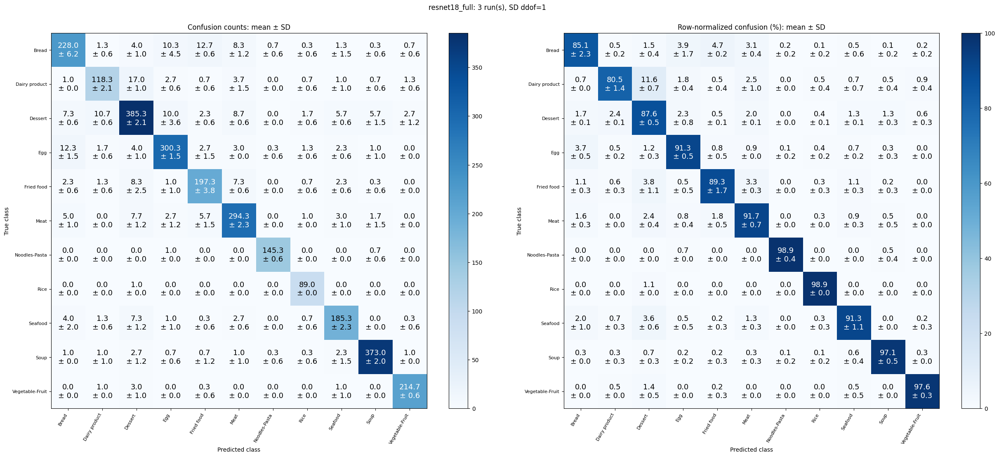

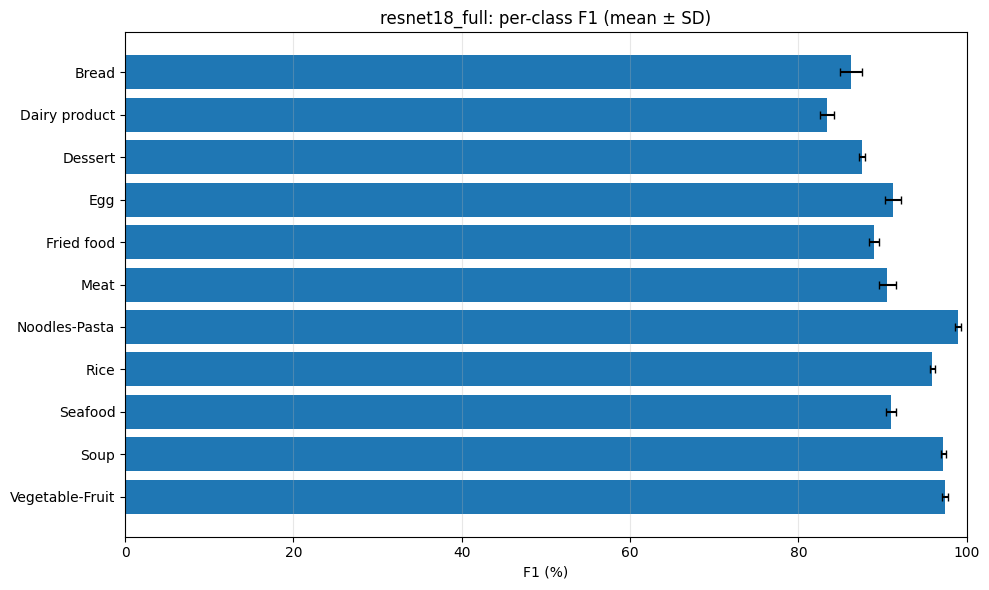


Model: resnet18_full | Confusion counts


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,228.0 ± 6.2,1.3 ± 0.6,4.0 ± 1.0,10.3 ± 4.5,12.7 ± 0.6,8.3 ± 1.2,0.7 ± 0.6,0.3 ± 0.6,1.3 ± 1.5,0.3 ± 0.6,0.7 ± 0.6
Dairy product,1.0 ± 0.0,118.3 ± 2.1,17.0 ± 1.0,2.7 ± 0.6,0.7 ± 0.6,3.7 ± 1.5,0.0 ± 0.0,0.7 ± 0.6,1.0 ± 1.0,0.7 ± 0.6,1.3 ± 0.6
Dessert,7.3 ± 0.6,10.7 ± 0.6,385.3 ± 2.1,10.0 ± 3.6,2.3 ± 0.6,8.7 ± 0.6,0.0 ± 0.0,1.7 ± 0.6,5.7 ± 0.6,5.7 ± 1.5,2.7 ± 1.2
Egg,12.3 ± 1.5,1.7 ± 0.6,4.0 ± 1.0,300.3 ± 1.5,2.7 ± 1.5,3.0 ± 0.0,0.3 ± 0.6,1.3 ± 0.6,2.3 ± 0.6,1.0 ± 1.0,0.0 ± 0.0
Fried food,2.3 ± 0.6,1.3 ± 0.6,8.3 ± 2.5,1.0 ± 1.0,197.3 ± 3.8,7.3 ± 0.6,0.0 ± 0.0,0.7 ± 0.6,2.3 ± 0.6,0.3 ± 0.6,0.0 ± 0.0
Meat,5.0 ± 1.0,0.0 ± 0.0,7.7 ± 1.2,2.7 ± 1.2,5.7 ± 1.5,294.3 ± 2.3,0.0 ± 0.0,1.0 ± 0.0,3.0 ± 1.0,1.7 ± 1.5,0.0 ± 0.0
Noodles-Pasta,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,145.3 ± 0.6,0.0 ± 0.0,0.0 ± 0.0,0.7 ± 0.6,0.0 ± 0.0
Rice,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,89.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
Seafood,4.0 ± 2.0,1.3 ± 0.6,7.3 ± 1.2,1.0 ± 1.0,0.3 ± 0.6,2.7 ± 0.6,0.0 ± 0.0,0.7 ± 0.6,185.3 ± 2.3,0.0 ± 0.0,0.3 ± 0.6


Row-normalized confusion: mean in percent, SD in percentage points


predicted_class,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
true_class,,,,,,,,,,,
Bread,85.1 ± 2.3%,0.5 ± 0.2%,1.5 ± 0.4%,3.9 ± 1.7%,4.7 ± 0.2%,3.1 ± 0.4%,0.2 ± 0.2%,0.1 ± 0.2%,0.5 ± 0.6%,0.1 ± 0.2%,0.2 ± 0.2%
Dairy product,0.7 ± 0.0%,80.5 ± 1.4%,11.6 ± 0.7%,1.8 ± 0.4%,0.5 ± 0.4%,2.5 ± 1.0%,0.0 ± 0.0%,0.5 ± 0.4%,0.7 ± 0.7%,0.5 ± 0.4%,0.9 ± 0.4%
Dessert,1.7 ± 0.1%,2.4 ± 0.1%,87.6 ± 0.5%,2.3 ± 0.8%,0.5 ± 0.1%,2.0 ± 0.1%,0.0 ± 0.0%,0.4 ± 0.1%,1.3 ± 0.1%,1.3 ± 0.3%,0.6 ± 0.3%
Egg,3.7 ± 0.5%,0.5 ± 0.2%,1.2 ± 0.3%,91.3 ± 0.5%,0.8 ± 0.5%,0.9 ± 0.0%,0.1 ± 0.2%,0.4 ± 0.2%,0.7 ± 0.2%,0.3 ± 0.3%,0.0 ± 0.0%
Fried food,1.1 ± 0.3%,0.6 ± 0.3%,3.8 ± 1.1%,0.5 ± 0.5%,89.3 ± 1.7%,3.3 ± 0.3%,0.0 ± 0.0%,0.3 ± 0.3%,1.1 ± 0.3%,0.2 ± 0.3%,0.0 ± 0.0%
Meat,1.6 ± 0.3%,0.0 ± 0.0%,2.4 ± 0.4%,0.8 ± 0.4%,1.8 ± 0.5%,91.7 ± 0.7%,0.0 ± 0.0%,0.3 ± 0.0%,0.9 ± 0.3%,0.5 ± 0.5%,0.0 ± 0.0%
Noodles-Pasta,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.7 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,98.9 ± 0.4%,0.0 ± 0.0%,0.0 ± 0.0%,0.5 ± 0.4%,0.0 ± 0.0%
Rice,0.0 ± 0.0%,0.0 ± 0.0%,1.1 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,98.9 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%,0.0 ± 0.0%
Seafood,2.0 ± 1.0%,0.7 ± 0.3%,3.6 ± 0.6%,0.5 ± 0.5%,0.2 ± 0.3%,1.3 ± 0.3%,0.0 ± 0.0%,0.3 ± 0.3%,91.3 ± 1.1%,0.0 ± 0.0%,0.2 ± 0.3%


,accuracy_ovr,precision,recall,f1,support
class,,,,,
Bread,0.9736 ± 0.0023,0.8737 ± 0.0113,0.8507 ± 0.0233,0.8619 ± 0.0130,268
Dairy product,0.9830 ± 0.0007,0.8659 ± 0.0036,0.8050 ± 0.0142,0.8343 ± 0.0083,147
Dessert,0.9604 ± 0.0012,0.8751 ± 0.0069,0.8758 ± 0.0047,0.8754 ± 0.0033,440
Egg,0.9791 ± 0.0025,0.9114 ± 0.0211,0.9129 ± 0.0046,0.9120 ± 0.0096,329
Fried food,0.9823 ± 0.0007,0.8863 ± 0.0066,0.8929 ± 0.0171,0.8895 ± 0.0058,221
Meat,0.9779 ± 0.0024,0.8947 ± 0.0129,0.9169 ± 0.0072,0.9057 ± 0.0099,321
Noodles-Pasta,0.9989 ± 0.0004,0.9910 ± 0.0078,0.9887 ± 0.0039,0.9898 ± 0.0034,147
Rice,0.9972 ± 0.0002,0.9303 ± 0.0056,0.9889 ± 0.0000,0.9587 ± 0.0030,90
Seafood,0.9868 ± 0.0008,0.9071 ± 0.0073,0.9130 ± 0.0114,0.9100 ± 0.0054,203


In [ ]:
multi_class_outputs = class_results(
	multi_seed_results,output_prefix=multi_prefix,save=SAVE_REPORTS,
)
